# CASMI26: data and validation

**Strand:** data and validation (Luke Devlin). **Feeds:** `report/01-Data`, the split section of
`report/02-Validation-and-Baseline`, and the cleaned data that the other four strands read.

The project asks how a neural spectrum encoder scales. The data is the training set of Kaggle's
CASMI26 competition: 2.5 million tandem mass spectra (MS/MS), each labelled with the molecule it
came from. This notebook does the groundwork for every model in the project:

1. gets the data and describes what is in the files;
2. explores the training spectra, with an eye on how they differ from the test set;
3. compares the dataset with the alternatives we considered;
4. cleans and bins the spectra;
5. builds the validation split that every model is scored on;
6. writes the cleaned spectra and the split to disk for the other strands.

**Manual step before running.** The data is licensed CC BY-NC 4.0 and stays out of the repo.
To download it you need a Kaggle account, to have accepted the
[competition rules](https://www.kaggle.com/competitions/enveda-CASMI26-molecule-id-mass-spectra/rules),
and a Kaggle API token in `~/.kaggle/`. Section 1 then downloads the files if they are not already
in the repo folder.

**Run time.** The full run takes a few minutes and stays under about 5 GB of memory, because the
3 GB training file is never loaded whole. Set `SUBSAMPLE = 0.05` in the first settings cell to run
everything on 5% of the molecules in about a minute.

A short glossary, since the rest of the notebook leans on these terms:

| Term | Meaning |
| --- | --- |
| MS/MS spectrum | A molecule is ionised, one ion (the *precursor*) is isolated and broken up, and the fragments are weighed. The spectrum is the list of fragment *peaks*: a mass-to-charge ratio (m/z) and an intensity each. |
| Adduct | What was attached to the molecule M to ionise it, such as `[M+H]+` (a proton) or `[M+Na]+` (sodium). It fixes the precursor m/z for a given molecule. |
| Collision energy | How hard the precursor was hit. Higher energy gives more, smaller fragments, so one molecule yields different spectra. |
| InChIKey | A 27-character hash of a structure. Its first 14 characters (`inchikey14`) encode the atom connectivity only, ignoring stereochemistry [(Heller et al., 2015)](https://doi.org/10.1186/s13321-015-0068-4). The competition counts a guess as correct if its `inchikey14` matches. |
| timsTOF | The Bruker instrument the hidden test set was measured on. |

## 0. Setup

In [1]:
# Install anything that is missing into the environment this kernel runs in.
import importlib.util
import subprocess
import sys

REQUIRED = ["polars", "pyarrow", "numpy", "matplotlib", "rdkit", "kagglehub"]
missing = [name for name in REQUIRED if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("installed:" if missing else "all packages already present", *missing)


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


installed: polars numpy matplotlib rdkit


In [2]:
import hashlib
import json
import os
import re
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pyarrow.parquet as pq

print("python", sys.version.split()[0], "| polars", pl.__version__, "| numpy", np.__version__)

python 3.14.0 | polars 2.1.0 | numpy 2.5.4


Every setting that changes a result lives in the next cell.

In [3]:
# ---- Switches ------------------------------------------------------------------------
SUBSAMPLE = 1.0          # fraction of molecules to use. 0.05 runs the notebook in about a minute.
WRITE_OUTPUTS = True     # write the cleaned spectra and the split (section 8)
RUN_SIMILARITY = True    # compare held-out with training molecules by fingerprint (section 7.5)

# ---- Exploration -----------------------------------------------------------------------
PEAK_SAMPLE_FRACTION = 0.04   # share of molecules whose peak lists are loaded for peak-level plots

# ---- Cleaning (section 5) --------------------------------------------------------------
MIN_REL_INTENSITY = 0.005     # drop peaks below 0.5% of the spectrum's tallest peak
MAX_PEAKS = 256               # then keep at most this many peaks, most intense first
PRECURSOR_WINDOW = 2.5        # drop peaks more than this many Da above the precursor mass
PRECURSOR_MZ_RANGE = (50.0, 1500.0)   # drop spectra whose precursor m/z is outside this range
MIN_PEAKS_TRAIN = 3           # a training spectrum needs at least this many peaks after cleaning
PPM_TOLERANCE = 20.0          # a precursor within this many ppm of its formula counts as consistent

# ---- Binning (section 6) -----------------------------------------------------------------
BIN_WIDTH = 0.1               # Da. Bin index = floor(m/z / BIN_WIDTH)
MAX_FRAGMENT_MZ = PRECURSOR_MZ_RANGE[1] + PRECURSOR_WINDOW   # no cleaned peak lies above this
N_BINS = int(np.ceil(MAX_FRAGMENT_MZ / BIN_WIDTH))            # length of a binned spectrum as a dense vector

# ---- Validation split (section 7) ----------------------------------------------------------
SPLIT_SALT = "casmi26-split-v1"   # changing this string reassigns every molecule
NP_VAL_FRACTION = 0.5             # natural-product examples: this share to validation, the rest to test
LIBRARY_HELD_OUT_FRACTION = 0.4   # molecules with timsTOF and library spectra: this share to each of val and test
TIMS_ONLY_SLICE = 0.0056          # timsTOF-only molecules: this share to each of class 2 val/test and class 3 val/test
N_SIMILARITY_QUERIES = 300        # held-out molecules per group in the similarity check (section 7.5)

# ---- Processing ------------------------------------------------------------------------------
BATCH_ROWS = 32_768           # spectra cleaned at a time, which bounds memory

In [4]:
# Table display and one plot style for the whole notebook.
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
pl.Config.set_thousands_separator(",")
pl.Config.set_float_precision(3)

INK, INK_SOFT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
# One colour per group of data, used the same way in every figure.
GROUP_COLOURS = {"enveda-180": BLUE, "enveda-np-examples": ORANGE, "public libraries": AQUA}
GROUPS = list(GROUP_COLOURS)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "axes.labelcolor": INK_SOFT,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "legend.frameon": False, "lines.linewidth": 2,
})


def stable_uniform(keys: pl.Series, salt: str) -> pl.Series:
    """Map each key to a number in [0, 1) that is identical on every machine and in every run.

    Python's own hash() changes between sessions and Polars' hash() between versions, so the
    split would differ between teammates. A cryptographic hash of the text does not.
    """
    values = [
        int.from_bytes(hashlib.blake2b(f"{salt}:{key}".encode(), digest_size=8).digest(), "big") / 2**64
        for key in keys.to_list()
    ]
    return pl.Series(keys.name, values, dtype=pl.Float64)


def megabytes(n_bytes: float) -> float:
    return n_bytes / 1e6

## 1. Getting the data

The files are looked for in the repo folder, then in Kaggle's input folder (for running on
Kaggle), and are downloaded with `kagglehub` as a last resort. Setting the environment variable
`CASMI26_DATA_DIR` overrides the search.

In [5]:
COMPETITION = "enveda-CASMI26-molecule-id-mass-spectra"


def find_repo_root(start: Path) -> Path:
    """The first folder at or above `start` that holds the git repo or the data."""
    for folder in [start, *start.parents]:
        if (folder / ".git").exists() or (folder / COMPETITION).exists():
            return folder
    return start


def find_data_dir(repo: Path) -> Path:
    candidates = [os.environ.get("CASMI26_DATA_DIR"), repo / COMPETITION, Path("/kaggle/input") / COMPETITION]
    for candidate in candidates:
        if candidate and (Path(candidate) / "train.parquet").exists():
            return Path(candidate)
    import kagglehub  # needs a Kaggle API token and the competition rules accepted

    return Path(kagglehub.competition_download(COMPETITION))


REPO = find_repo_root(Path.cwd())
DATA_DIR = find_data_dir(REPO)
TRAIN, TEST = DATA_DIR / "train.parquet", DATA_DIR / "test.parquet"

# Everything this notebook writes goes next to the data. The repo's .gitignore already ignores
# any path starting with the competition name, so none of it can be committed by accident.
suffix = "-derived" if SUBSAMPLE >= 1 else "-derived-subsample"
DERIVED_DIR = Path(os.environ.get("CASMI26_DERIVED_DIR", REPO / f"{COMPETITION}{suffix}"))

print("data:   ", DATA_DIR)
print("outputs:", DERIVED_DIR)
pl.DataFrame(
    {"file": [p.name for p in sorted(DATA_DIR.iterdir())],
     "MB": [round(megabytes(p.stat().st_size), 2) for p in sorted(DATA_DIR.iterdir())]}
)

data:    /home/luke/Desktop/DST_Sprints/Group-Sprint-2/enveda-CASMI26-molecule-id-mass-spectra
outputs: /home/luke/Desktop/DST_Sprints/Group-Sprint-2/enveda-CASMI26-molecule-id-mass-spectra-derived


file,MB
str,f64
"""sample_submission.csv""",0.040
"""test.parquet""",4.850
"""train.parquet""","3,033.290"


## 2. What is in the files

### 2.1 How the training file is laid out

`train.parquet` is a Parquet file: the table is cut into *row groups*, and inside each row group
every column is stored and compressed separately. The file's footer records where each piece
sits, so we can read the layout without reading any data.

In [6]:
train_file = pq.ParquetFile(TRAIN, memory_map=True)
layout = train_file.metadata
N_ROWS, N_ROW_GROUPS = layout.num_rows, layout.num_row_groups
ROW_GROUP_ROWS = [layout.row_group(i).num_rows for i in range(N_ROW_GROUPS)]
ROW_GROUP_START = [sum(ROW_GROUP_ROWS[:i]) for i in range(N_ROW_GROUPS)]
print(f"{N_ROWS:,} rows in {N_ROW_GROUPS} row groups, {layout.num_columns} columns, written by {layout.created_by}")

# Bytes per column, summed over the row groups.
column_bytes = {}
for i in range(N_ROW_GROUPS):
    group = layout.row_group(i)
    for j in range(group.num_columns):
        chunk = group.column(j)
        name = chunk.path_in_schema.split(".")[0]
        stored, unpacked = column_bytes.get(name, (0, 0))
        column_bytes[name] = (stored + chunk.total_compressed_size, unpacked + chunk.total_uncompressed_size)

schema = train_file.schema_arrow
columns = pl.DataFrame({
    "column": list(column_bytes),
    "type": [str(schema.field(name).type).replace("element: ", "") for name in column_bytes],
    "MB on disk": [megabytes(stored) for stored, _ in column_bytes.values()],
    "MB unpacked": [megabytes(unpacked) for _, unpacked in column_bytes.values()],
}).with_columns((pl.col("MB on disk") / pl.col("MB on disk").sum() * 100).alias("% of file"))
PEAK_COLUMNS = ["ms2_mzs", "ms2_normalized_intensities"]
peak_share = columns.filter(pl.col("column").is_in(PEAK_COLUMNS))["% of file"].sum()
print(f"the two peak-list columns hold {peak_share:.1f}% of the file")
columns

2,539,608 rows in 21 row groups, 18 columns, written by parquet-cpp-arrow version 23.0.1
the two peak-list columns hold 98.3% of the file


column,type,MB on disk,MB unpacked,% of file
str,str,f64,f64,f64
"""ingest_lib""","""string""",0.010,0.009,0.000
"""normalized_smiles""","""string""",5.722,19.527,0.189
"""inchikey""","""string""",4.592,12.785,0.151
"""inchikey14""","""string""",4.594,8.467,0.151
"""molecular_formula""","""string""",2.392,4.788,0.079
"""ionization_mode""","""string""",0.231,0.340,0.008
"""instrument_type""","""string""",0.280,0.519,0.009
"""adduct""","""string""",0.477,1.103,0.016
"""adduct_orig""","""string""",0.478,1.104,0.016


The two peak-list columns are almost the whole file. Because Parquet stores columns separately,
anything that needs only the other sixteen columns reads under 2% of the bytes. The next cell
reads every non-peak column for all 2.5 million spectra and times it. This is the property that
lets the same analysis run when the file is 1000 times larger: the cost follows the columns
touched, not the file size.

In [7]:
SCALAR_COLUMNS = [
    "ingest_lib", "inchikey14", "molecular_formula", "ionization_mode", "instrument_type", "adduct",
    "adduct_orig", "precursor_mz", "precursor_error_ppm", "num_peaks", "base_peak_intensity",
    "collision_energy_orig", "collision_energy_orig_units",
]
started = time.perf_counter()
meta = (
    pl.scan_parquet(TRAIN)
    .with_row_index("row_id")            # the row number in train.parquet is our spectrum id
    .select("row_id", *SCALAR_COLUMNS, pl.col("collision_energy_ev").list.len().alias("n_collision_energies"))
    .collect()
)
print(f"read {meta.width} columns x {meta.height:,} rows in {time.perf_counter() - started:.2f} s, "
      f"{meta.estimated_size('mb'):.0f} MB in memory")

# The subsample switch: keep a fixed, hash-chosen share of molecules and all of their spectra.
if SUBSAMPLE < 1:
    molecule_keys = meta["inchikey14"].unique()
    KEPT_MOLECULES = molecule_keys.filter(stable_uniform(molecule_keys, "subsample") < SUBSAMPLE)
    meta = meta.filter(pl.col("inchikey14").is_in(KEPT_MOLECULES.implode()))
    print(f"SUBSAMPLE = {SUBSAMPLE}: kept {KEPT_MOLECULES.len():,} molecules, {meta.height:,} spectra")
else:
    KEPT_MOLECULES = None

read 15 columns x 2,539,608 rows in 0.27 s, 264 MB in memory


The row groups are not alike. The figure shows the unpacked size of each one.

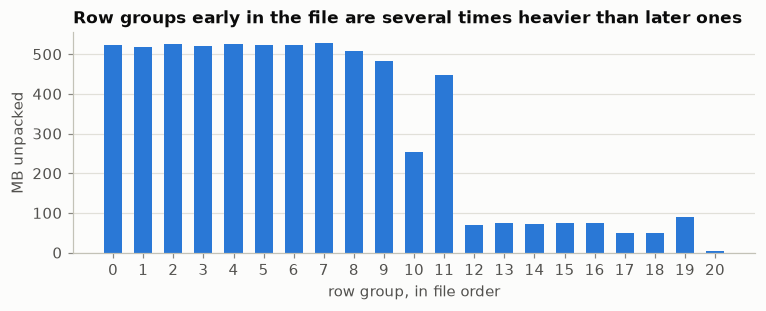

In [8]:
group_mb = [megabytes(layout.row_group(i).total_byte_size) for i in range(N_ROW_GROUPS)]
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.bar(range(N_ROW_GROUPS), group_mb, width=0.6, color=BLUE)
ax.set_xticks(range(N_ROW_GROUPS))
ax.set_xlabel("row group, in file order")
ax.set_ylabel("MB unpacked")
ax.set_title("Row groups early in the file are several times heavier than later ones")
ax.grid(axis="x", visible=False)
plt.show()

The reason is in section 3.1: the file is sorted by source library, and the library that fills
the first row groups has far more peaks per spectrum. Two practical consequences:

- **The first rows are not a sample.** `head(100_000)` returns one library on one instrument.
  Every subsample in this notebook is drawn by hashing the molecule instead.
- **Row count is a poor measure of work.** A benchmark "per 100,000 rows" depends on which rows.
  Peaks are the better unit, and section 8 reports both.

### 2.2 The columns

One row is one spectrum. The descriptions are our reading of the data; the checks behind them
are in section 3.

| Column | What it holds |
| --- | --- |
| `ingest_lib` | The source library the spectrum came from. Eleven values. |
| `normalized_smiles` | The molecule's structure as a SMILES string. This is what we must predict. |
| `inchikey`, `inchikey14` | The structure's InChIKey and its first 14 characters. `inchikey14` is our molecule identifier throughout. |
| `molecular_formula` | For example `C22H23N3O4`. A trailing `+` or `-` marks a permanently charged molecule. |
| `ionization_mode` | `positive` or `negative`. |
| `instrument_type` | Free text copied from the source library. |
| `adduct`, `adduct_orig` | The adduct in a normalised notation, and as the source library wrote it. |
| `precursor_mz` | The m/z of the ion that was fragmented. |
| `precursor_error_ppm` | The gap between `precursor_mz` and the value expected from formula and adduct, in parts per million. Section 3.6 shows why we recompute it. |
| `ms2_mzs`, `ms2_normalized_intensities` | The peak list: fragment m/z values in ascending order, and intensities scaled so the tallest peak is 1. |
| `num_peaks` | The length of the peak list. |
| `base_peak_intensity` | The tallest peak's raw detector count. Present for three libraries only. |
| `collision_energy_ev`, `collision_energy_orig`, `collision_energy_orig_units` | Collision energies as a list of numbers, as originally written, and the unit. |

Missing values, per column:

In [9]:
nulls = meta.null_count().unpivot(variable_name="column", value_name="missing")
nulls.filter(pl.col("missing") > 0).with_columns((pl.col("missing") / meta.height * 100).alias("% of spectra"))

column,missing,% of spectra
str,u32,f64
"""instrument_type""","33,053",1.302
"""precursor_error_ppm""","4,286",0.169
"""base_peak_intensity""","1,163,138",45.800
"""collision_energy_orig""","320,464",12.619
"""n_collision_energies""","337,443",13.287


### 2.3 The test file is a placeholder

`test.parquet` has the spectrum columns but no labels. It adds a `molecule_id` that groups the
spectra of one unknown molecule, since a submission gives one ranked list per molecule. Kaggle
swaps this file for the hidden test set when a submission notebook runs. The check below matches
every row of the local file against the training data on seven spectrum-level columns.

In [10]:
test = pl.read_parquet(TEST)
test_only = [c for c in test.columns if c not in schema.names]
train_only = [c for c in schema.names if c not in test.columns]
print(f"{test.height:,} spectra of {test['molecule_id'].n_unique():,} molecules")
print("columns only in test: ", test_only)
print("columns only in train:", train_only)

match_on = ["precursor_mz", "adduct", "num_peaks", "base_peak_intensity", "collision_energy_orig",
            "ionization_mode", "instrument_type"]
test_keys = test.with_columns(pl.col("ms2_mzs").list.len().cast(pl.Int64).alias("num_peaks"))
matched = test_keys.select("molecule_id", "spectrum_id", *match_on).join(
    meta.select("row_id", "ingest_lib", "inchikey14", *match_on), on=match_on, how="inner")
per_molecule = matched.group_by("molecule_id").agg(pl.col("inchikey14").n_unique())
print(f"{matched['spectrum_id'].n_unique():,} of {test.height:,} test spectra are rows of train.parquet, "
      f"from libraries {matched['ingest_lib'].unique().to_list()}")
print(f"each test molecule_id maps to {per_molecule['inchikey14'].max()} inchikey14")

1,213 spectra of 400 molecules
columns only in test:  ['molecule_id', 'spectrum_id']
columns only in train: ['ingest_lib', 'normalized_smiles', 'inchikey', 'inchikey14', 'molecular_formula', 'adduct_orig', 'precursor_error_ppm', 'num_peaks']
1,213 of 1,213 test spectra are rows of train.parquet, from libraries ['enveda-180']
each test molecule_id maps to 1 inchikey14


On the full data every one of the 1,213 local test spectra is a row of the training file, all
from the `enveda-180` library, and each `molecule_id` corresponds to exactly one `inchikey14`.
Three things follow:

- **The local test file cannot be used for validation.** Its answers are in the training data.
  We have to build our own held-out set, which is section 7.
- The test file shows the *format* of the hidden test set: all timsTOF, 1 to 9 spectra per
  molecule here, and a specific set of adducts. Section 7 copies that format.
- A "molecule" in the competition is an `inchikey14`, which confirms it as the unit to split on.

## 3. Exploring the training data

Sections 3.1 to 3.7 use the non-peak columns of every spectrum, loaded above. Sections 3.8 and
3.9 need the peak lists, so they use a sample of molecules.

First, four derived columns that the rest of the notebook relies on. The source libraries
describe instruments, formulas and adducts as text; these helpers turn that text into numbers.

In [11]:
def instrument_family(label: str) -> str:
    """Collapse the libraries' free-text instrument labels into six families."""
    text = label.lower()
    if text in ("", "nan", "n/a", "unknown"):
        return "unknown"
    if "timstof" in text:
        return "timsTOF"
    if any(key in text for key in ("orbitrap", "qft", "itft", "-ft", "hybrid ft", "exactive", "qehf")):
        return "Orbitrap/FT"
    if any(key in text for key in ("tof", "maxis", "synapt", "impact")):
        return "QTOF/TOF"
    if "qq" in text or "quattro" in text or text.endswith("-q"):
        return "triple quadrupole"
    if "trap" in text or text.endswith("it") or "ltq" in text:
        return "ion trap"
    return "other"


# Monoisotopic masses in Da (the mass of the most abundant isotope), from the IUPAC atomic-mass tables.
ELEMENT_MASS = {
    "H": 1.00782503207, "C": 12.0, "N": 14.0030740048, "O": 15.99491461956, "S": 31.972071,
    "P": 30.97376163, "F": 18.99840322, "Cl": 34.96885268, "Br": 78.9183371, "I": 126.904473,
    "B": 11.0093054, "Si": 27.9769265325, "As": 74.9215965, "Se": 79.9165213, "Sn": 119.9021947,
    "Li": 7.01600455, "Na": 22.9897692809, "K": 38.96370668, "Mg": 23.9850417, "Ca": 39.96259098,
    "Fe": 55.9349375, "Cu": 62.9295975, "Zn": 63.9291422, "Ag": 106.905097,
}
ELECTRON_MASS = 0.00054857990946
FORMULA = re.compile(r"(?:[A-Z][a-z]?\d*)+")
CHARGE_SUFFIX = re.compile(r"[+-]\d*$")
ELEMENT_COUNT = re.compile(r"([A-Z][a-z]?)(\d*)")
ADDUCT = re.compile(r"\[(\d*)M((?:[+-]\d*[A-Za-z][A-Za-z0-9]*)*)\](\d*)([+-])")
ADDUCT_TERM = re.compile(r"([+-])(\d*)([A-Za-z][A-Za-z0-9]*)")


def formula_mass(formula: str) -> float | None:
    """Monoisotopic mass of a formula such as C22H23N3O4. A trailing charge such as + or +2 is ignored."""
    formula = CHARGE_SUFFIX.sub("", formula)
    if not FORMULA.fullmatch(formula):
        return None
    total = 0.0
    for element, count in ELEMENT_COUNT.findall(formula):
        if element not in ELEMENT_MASS:
            return None
        total += ELEMENT_MASS[element] * int(count or 1)
    return total


def adduct_parts(adduct: str) -> tuple[int, float, int] | None:
    """Split an adduct into (number of molecules, mass added in Da, charge).

    '[2M+Na]+' gives (2, 22.99, +1) and '[M+CH2O2-H]-' gives (1, 44.998, -1).
    Returns None for notation that is not a sum of chemical formulas, such as '[Cat]2+'.
    """
    match = ADDUCT.fullmatch(adduct)
    if match is None:
        return None
    shift = 0.0
    for sign, multiple, fragment in ADDUCT_TERM.findall(match.group(2)):
        mass = formula_mass(fragment)
        if mass is None:
            return None
        shift += (1 if sign == "+" else -1) * int(multiple or 1) * mass
    charge = int(match.group(3) or 1) * (1 if match.group(4) == "+" else -1)
    return int(match.group(1) or 1), shift, charge


# Look-up tables, built once from the distinct values and joined on wherever needed.
INSTRUMENT_FAMILY = {label: instrument_family(label) for label in meta["instrument_type"].drop_nulls().unique().to_list()}
parsed = {adduct: adduct_parts(adduct) for adduct in meta["adduct"].unique().to_list()}
ADDUCTS = pl.DataFrame(
    [{"adduct": adduct, "n_molecules": parts[0], "adduct_shift": parts[1], "charge": parts[2]}
     for adduct, parts in parsed.items() if parts is not None],
    schema={"adduct": pl.String, "n_molecules": pl.Int8, "adduct_shift": pl.Float64, "charge": pl.Int8},
)
formulas = meta["molecular_formula"].unique()
FORMULAS = pl.DataFrame({
    "molecular_formula": formulas,
    "mono_mass": formulas.map_elements(formula_mass, return_dtype=pl.Float64),
})
print(f"{len(INSTRUMENT_FAMILY)} instrument labels, {len(parsed)} adducts "
      f"({[a for a, p in parsed.items() if p is None]} not parsed), "
      f"{FORMULAS.height:,} formulas ({FORMULAS['mono_mass'].null_count()} not parsed)")


def annotate(spectra: pl.DataFrame) -> pl.DataFrame:
    """Add the derived columns. Works on the metadata table and on any slice of the training file."""
    return (
        spectra
        .join(ADDUCTS, on="adduct", how="left")
        .join(FORMULAS, on="molecular_formula", how="left")
        .with_columns(
            pl.col("instrument_type").replace_strict(INSTRUMENT_FAMILY, default="unknown").alias("instrument_family"),
            pl.when(pl.col("ingest_lib").str.starts_with("enveda")).then(pl.col("ingest_lib"))
            .otherwise(pl.lit("public libraries")).alias("group"),
            (pl.col("n_molecules") > 1).alias("is_dimer"),
            # The m/z the precursor should have, from the formula and the adduct. A positive ion has
            # lost electrons and a negative ion has gained them, hence the electron-mass term.
            ((pl.col("n_molecules") * pl.col("mono_mass") + pl.col("adduct_shift")
              - pl.col("charge") * ELECTRON_MASS) / pl.col("charge").abs()).alias("expected_mz"),
        )
        .with_columns(
            ((pl.col("precursor_mz") - pl.col("expected_mz")) / pl.col("expected_mz") * 1e6).alias("ppm_error"),
            ((pl.col("ionization_mode") == "positive") == (pl.col("charge") > 0)).alias("mode_matches_adduct"),
            pl.col("precursor_mz").is_between(*PRECURSOR_MZ_RANGE).alias("precursor_in_range"),
        )
        # A spectrum is usable only if all three checks that need no peaks pass (section 5).
        .with_columns(
            (pl.col("charge").is_not_null() & pl.col("mode_matches_adduct") & pl.col("precursor_in_range"))
            .fill_null(False).alias("metadata_ok")
        )
    )


meta = annotate(meta).sort("row_id")
meta.select("row_id", "ingest_lib", "group", "instrument_family", "adduct", "n_molecules", "charge",
            "precursor_mz", "expected_mz", "ppm_error").head(3)

82 instrument labels, 121 adducts (['[Cat]2+'] not parsed), 51,291 formulas (0 not parsed)


row_id,ingest_lib,group,instrument_family,adduct,n_molecules,charge,precursor_mz,expected_mz,ppm_error
u32,str,str,str,str,i8,i8,f64,f64,f64
0,"""drug_plus""","""public libraries""","""unknown""","""[M+H]+""",1,1,330.124,330.124,-0.010
1,"""drug_plus""","""public libraries""","""unknown""","""[M+K]+""",1,1,432.132,432.132,-0.033
2,"""drug_plus""","""public libraries""","""unknown""","""[M+Na]+""",1,1,422.174,422.174,-0.017


`group` is the split we use in most figures: the two Enveda libraries, which were measured on the
test instrument, and everything else pooled as "public libraries".

### 3.1 Eleven source libraries

In [12]:
libraries = (
    meta.group_by("ingest_lib")
    .agg(
        pl.col("group").first(),
        pl.len().alias("spectra"),
        pl.col("inchikey14").n_unique().alias("molecules"),
        pl.col("instrument_family").mode().first().alias("main instrument"),
        pl.col("num_peaks").quantile(0.5, "nearest").cast(pl.Int64).alias("median peaks"),
        pl.col("row_id").min().alias("first row"),
        pl.col("row_id").max().alias("last row"),
    )
    .with_columns((pl.col("spectra") / meta.height * 100).alias("% of spectra"))
    .sort("first row")
)
libraries.select("ingest_lib", "spectra", "% of spectra", "molecules", "main instrument", "median peaks",
                 "first row", "last row")

ingest_lib,spectra,% of spectra,molecules,main instrument,median peaks,first row,last row
str,u32,f64,u32,str,i64,u32,u32
"""drug_plus""","2,545",0.100,"2,539","""unknown""",108,0,"2,544"
"""enveda-180""","1,153,785",45.432,"182,941","""timsTOF""",138,"2,545","1,156,329"
"""gnps""","220,849",8.696,"45,750","""Orbitrap/FT""",46,"1,156,330","1,377,178"
"""masaryk""",652,0.026,416,"""Orbitrap/FT""",9,"1,377,179","1,377,830"
"""massbank""","101,727",4.006,"9,180","""QTOF/TOF""",11,"1,377,831","1,479,557"
"""mona""","92,416",3.639,"11,681","""Orbitrap/FT""",57,"1,479,558","1,571,973"
"""msdial""","40,765",1.605,"9,127","""unknown""",11,"1,571,974","1,612,738"
"""pluskal_ms2""","527,581",20.774,"46,821","""Orbitrap/FT""",21,"1,612,739","2,140,319"
"""riken""","347,171",13.670,"15,892","""QTOF/TOF""",9,"2,140,320","2,487,490"


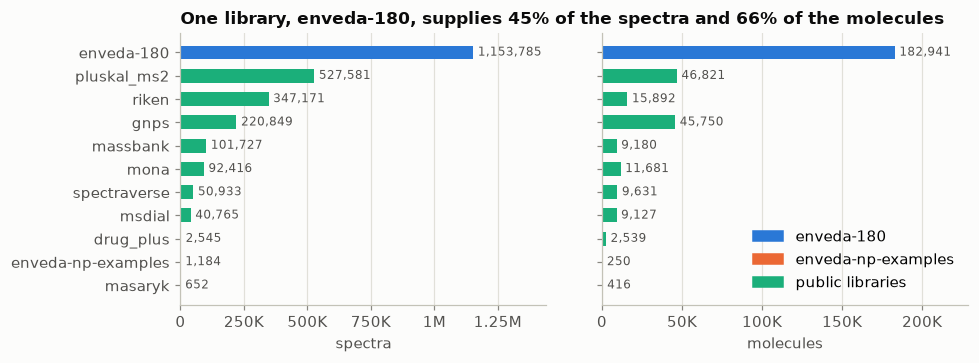

In [13]:
by_size = libraries.sort("spectra")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, column in zip(axes, ["spectra", "molecules"]):
    bars = ax.barh(by_size["ingest_lib"], by_size[column], height=0.6,
                   color=[GROUP_COLOURS[g] for g in by_size["group"]])
    ax.bar_label(bars, labels=[f"{v:,}" for v in by_size[column]], padding=3, color=INK_SOFT, fontsize=8)
    ax.set_xlabel(column)
    ax.set_xlim(0, by_size[column].max() * 1.25)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1e6:g}M" if v >= 1e6 else f"{v / 1e3:g}K" if v else "0")
    ax.grid(axis="y", visible=False)
axes[0].set_title("One library, enveda-180, supplies 45% of the spectra and 66% of the molecules")
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLOURS.values()],
               labels=GROUPS, loc="lower right")
plt.tight_layout()
plt.show()

- `enveda-180` is Enveda's own library. Its press release describes it as about 1.16 million
  spectra of 184,330 *synthetic* small molecules
  ([Enveda, 2026](https://www.businesswire.com/news/home/20260915334355/en/Enveda-Is-Launching-the-Next-AlphaFold-Contest.-This-Time-to-Solve-the-Structures-of-90-of-Biological-Molecules-That-No-One-Can-Identify.)),
  which matches the 1,153,785 spectra of 182,941 molecules here.
- `enveda-np-examples` is tiny, 1,184 spectra of 250 molecules, but it is the only other data from
  the test instrument. Section 3.10 shows it is also the only data that looks like the test set.
- The other nine are public or academic libraries, mostly measured on Orbitrap instruments.
- The `first row` and `last row` columns confirm that the file is sorted by library, as section
  2.1 suggested.

### 3.2 Molecules

There are 275,810 distinct molecules. How many spectra does each have, and do the libraries
share molecules?

In [14]:
molecules = meta.group_by("inchikey14").agg(
    pl.len().alias("spectra"),
    pl.col("ingest_lib").n_unique().alias("libraries"),
    (pl.col("instrument_family") == "timsTOF").sum().alias("timstof_spectra"),
    (pl.col("instrument_family") != "timsTOF").sum().alias("other_spectra"),
)
print(f"{molecules.height:,} molecules, {meta.height / molecules.height:.1f} spectra each on average")
quantiles = [0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1.0]
pl.DataFrame({"quantile": quantiles,
              "spectra per molecule": [int(molecules["spectra"].quantile(q, "nearest")) for q in quantiles]})

275,810 molecules, 9.2 spectra each on average


quantile,spectra per molecule
f64,i64
0.050,1
0.250,4
0.500,6
0.750,9
0.950,21
0.990,79
1.000,"1,468"


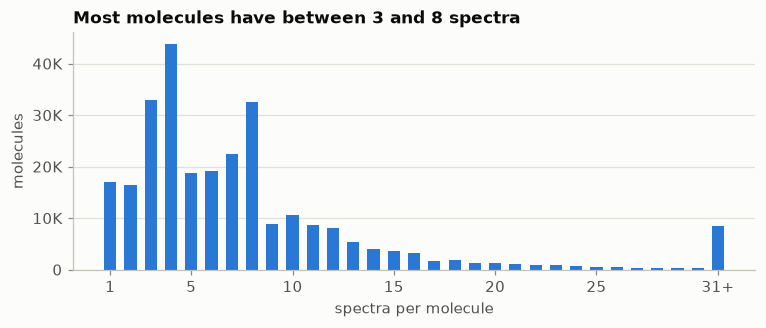

In [15]:
CAP = 30
counts = np.bincount(np.minimum(molecules["spectra"].to_numpy(), CAP + 1), minlength=CAP + 2)[1:]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(range(1, CAP + 2), counts, width=0.6, color=BLUE)
ax.set_xticks([1, 5, 10, 15, 20, 25, CAP + 1], ["1", "5", "10", "15", "20", "25", f"{CAP + 1}+"])
ax.set_xlabel("spectra per molecule")
ax.set_ylabel("molecules")
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1e3:g}K" if v else "0")
ax.set_title("Most molecules have between 3 and 8 spectra")
ax.grid(axis="x", visible=False)
plt.show()

Almost every molecule has several spectra: different adducts, collision energies and libraries.
Two spectra of one molecule look alike, so a model that has seen one can recognise the other
without having learned any chemistry. This is why section 7 splits by molecule and never by
spectrum.

The heat map shows how much the libraries overlap. Each cell is the share of the row library's
molecules that also appear in the column library.

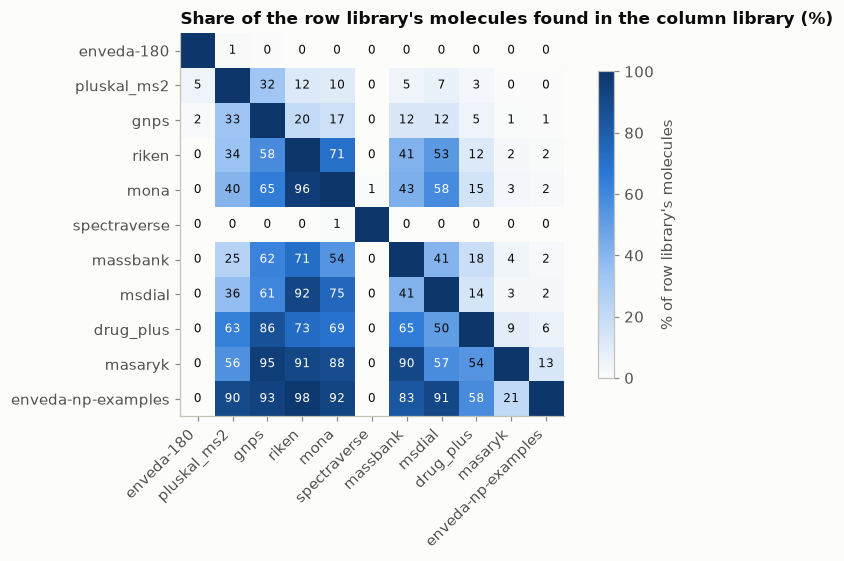

molecules with timsTOF spectra: 183,191; of these, also measured on another instrument: 2,538 (1.4%)


In [16]:
library_molecules = meta.select("ingest_lib", "inchikey14").unique()
shared = (
    library_molecules.join(library_molecules, on="inchikey14", suffix="_other")
    .group_by("ingest_lib", "ingest_lib_other").len()
)
order = libraries.sort("molecules", descending=True)["ingest_lib"].to_list()
size = dict(zip(libraries["ingest_lib"], libraries["molecules"]))
overlap = np.zeros((len(order), len(order)))
for row_lib, col_lib, n in shared.iter_rows():
    overlap[order.index(row_lib), order.index(col_lib)] = n / size[row_lib] * 100

blues = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", [SURFACE, "#9ec5f4", "#2a78d6", "#0d366b"])
fig, ax = plt.subplots(figsize=(7.5, 5.2))
image = ax.imshow(overlap, cmap=blues, vmin=0, vmax=100)
ax.set_xticks(range(len(order)), order, rotation=45, ha="right")
ax.set_yticks(range(len(order)), order)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j:
            ax.text(j, i, f"{overlap[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if overlap[i, j] > 55 else INK)
ax.set_title("Share of the row library's molecules found in the column library (%)")
ax.grid(visible=False)
fig.colorbar(image, ax=ax, shrink=0.8, label="% of row library's molecules")
plt.tight_layout()
plt.show()

both = molecules.filter((pl.col("timstof_spectra") > 0) & (pl.col("other_spectra") > 0)).height
tims = molecules.filter(pl.col("timstof_spectra") > 0).height
print(f"molecules with timsTOF spectra: {tims:,}; of these, also measured on another instrument: {both:,} "
      f"({both / max(tims, 1):.1%})")

- The public libraries overlap heavily with each other. `riken` contains most of `msdial` and
  `mona`, for example, so the same molecule often arrives from several libraries.
- `enveda-180` is close to disjoint from everything else: about 1% of its molecules appear in a
  public library.
- All 250 `enveda-np-examples` molecules appear in public libraries, and none in `enveda-180`.
- `spectraverse` shares molecules with almost nothing. We keep it, but note that it behaves like
  a separate dataset.

So only 2,538 of the 183,191 molecules measured on the test instrument were also measured on
another one. That number limits how we can simulate test class 1 in section 7.

### 3.3 Instruments

The `instrument_type` column has 82 distinct labels, with the same instrument written several
ways (`QTOF`, `qTof`, `qtof`, `Q-TOF`, `LC-ESI-QTOF`). The table groups them into six families, plus
`unknown` where the label is missing or says nothing.

In [17]:
(
    meta.group_by("instrument_family")
    .agg(pl.len().alias("spectra"), pl.col("inchikey14").n_unique().alias("molecules"),
         pl.col("instrument_type").n_unique().alias("labels in the file"),
         pl.col("ingest_lib").n_unique().alias("libraries"))
    .with_columns((pl.col("spectra") / meta.height * 100).alias("% of spectra"))
    .sort("spectra", descending=True)
)

instrument_family,spectra,molecules,labels in the file,libraries,% of spectra
str,u32,u32,u32,u32,f64
"""timsTOF""","1,154,969","183,191",1,2,45.478
"""Orbitrap/FT""","950,640","70,281",26,8,37.433
"""QTOF/TOF""","338,148","36,085",25,6,13.315
"""triple quadrupole""","36,364","2,509",12,5,1.432
"""unknown""","34,698","10,858",4,7,1.366
"""ion trap""","24,404","4,918",10,6,0.961
"""other""",385,190,5,4,0.015


45% of the spectra come from the test instrument, and all of them from the two Enveda libraries.
The rest are mostly Orbitrap and QTOF. Different instruments fragment differently and report
masses to different precision, so a model has to transfer across instruments to use the public
half of the data at all.

### 3.4 Ion modes and adducts

The figure shows the eight most common adducts as a share of each group's spectra. The fourth
panel is the local test file, as a guide to what the hidden test set contains.

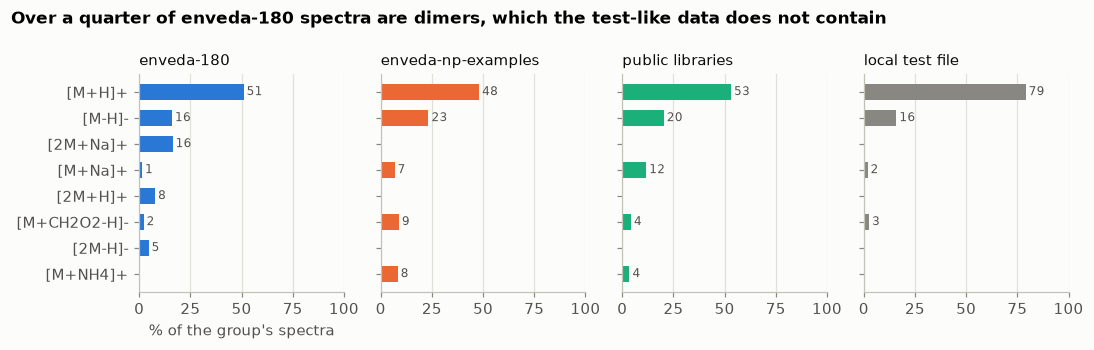

121 distinct adducts; 96.2% of spectra use the top eight
ionisation mode: 74.8% positive
spectra whose ionisation mode contradicts the sign of the adduct: 6,087
spectra whose adduct could not be parsed: 15


group,% dimer adducts
str,f64
"""enveda-180""",28.725
"""enveda-np-examples""",0.000
"""public libraries""",0.703


In [18]:
test_adducts = test.group_by("adduct").len().with_columns(pl.lit("local test file").alias("group"))
adduct_share = (
    pl.concat([meta.group_by("group", "adduct").len(), test_adducts.select("group", "adduct", "len")])
    .with_columns((pl.col("len") / pl.col("len").sum().over("group") * 100).alias("share"))
)
top_adducts = meta.group_by("adduct").len().sort("len", descending=True)["adduct"].head(8).to_list()
panels = GROUPS + ["local test file"]
fig, axes = plt.subplots(1, len(panels), figsize=(10, 3.2), sharey=True, sharex=True)
for ax, group in zip(axes, panels):
    lookup = dict(adduct_share.filter(pl.col("group") == group).select("adduct", "share").iter_rows())
    values = [lookup.get(adduct, 0.0) for adduct in top_adducts[::-1]]
    bars = ax.barh(top_adducts[::-1], values, height=0.6, color=GROUP_COLOURS.get(group, GREY))
    ax.bar_label(bars, labels=[f"{v:.0f}" if v >= 0.5 else "" for v in values], padding=2, color=INK_SOFT, fontsize=8)
    ax.set_title(group, fontweight="normal", fontsize=10)
    ax.set_xlim(0, 100)
    ax.grid(axis="y", visible=False)
axes[0].set_xlabel("% of the group's spectra")
fig.suptitle("Over a quarter of enveda-180 spectra are dimers, which the test-like data does not contain",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()

mismatch = meta.filter(~pl.col("mode_matches_adduct")).height
print(f"{meta['adduct'].n_unique()} distinct adducts; {meta['adduct'].is_in(top_adducts).mean():.1%} of spectra use the top eight")
print(f"ionisation mode: {(meta['ionization_mode'] == 'positive').mean():.1%} positive")
print(f"spectra whose ionisation mode contradicts the sign of the adduct: {mismatch:,}")
print(f"spectra whose adduct could not be parsed: {meta['charge'].null_count():,}")
meta.group_by("group").agg(pl.col("is_dimer").mean().mul(100).alias("% dimer adducts")).sort("group")

- `[M+H]+` dominates everywhere, and three quarters of all spectra are positive mode.
- **Dimers.** 29% of `enveda-180` spectra are dimer adducts such as `[2M+Na]+`: two molecules
  stuck to one ion, so the precursor is about twice the molecule's mass. Neither
  `enveda-np-examples` nor the local test file contains a single dimer. We therefore keep dimers
  for training but leave them out of the validation queries (section 7).
- **Two small defects.** 6,087 spectra are labelled with an ionisation mode that contradicts the
  sign of their adduct, for example `[M-H]-` in positive mode. We cannot tell which of the two
  is wrong, so section 5 drops them. Fifteen spectra use the notation `[Cat]2+`, which gives no
  mass, and are dropped too.

### 3.5 Precursor m/z

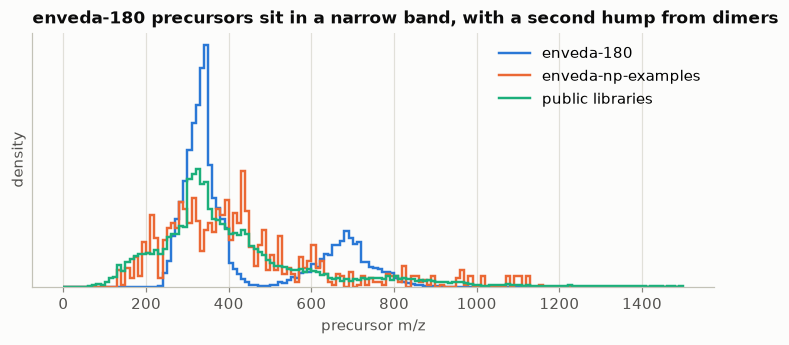

ingest_lib,min,median,max,below 50,above 1500
str,f64,f64,f64,u32,u32
"""drug_plus""",32.050,322.176,"1,736.007",1,2
"""enveda-180""",235.088,347.234,999.359,0,0
"""enveda-np-examples""",132.030,387.651,"1,153.602",0,0
"""gnps""",2.000,363.146,"3,355.600",22,329
"""masaryk""",74.072,295.157,886.532,0,0
"""massbank""",46.000,297.123,"1,978.000",10,105
"""mona""",46.000,334.238,"2,430,333.000",3,241
"""msdial""",46.065,374.160,"2,679.487",9,115
"""pluskal_ms2""",115.004,343.111,"1,807.837",0,72


In [19]:
edges = np.arange(0, 1501, 10)
fig, ax = plt.subplots(figsize=(8, 3))
for group in GROUPS:
    values = meta.filter(pl.col("group") == group)["precursor_mz"].to_numpy()
    density, _ = np.histogram(values, bins=edges, density=True)
    ax.stairs(density, edges, color=GROUP_COLOURS[group], linewidth=1.6, label=group)
ax.set_xlabel("precursor m/z")
ax.set_ylabel("density")
ax.set_yticks([])
ax.set_title("enveda-180 precursors sit in a narrow band, with a second hump from dimers")
ax.legend()
plt.show()

low, high = PRECURSOR_MZ_RANGE
(
    meta.group_by("ingest_lib")
    .agg(pl.col("precursor_mz").min().alias("min"), pl.col("precursor_mz").median().alias("median"),
         pl.col("precursor_mz").max().alias("max"),
         (pl.col("precursor_mz") < low).sum().alias(f"below {low:g}"),
         (pl.col("precursor_mz") > high).sum().alias(f"above {high:g}"))
    .sort("ingest_lib")
)

- `enveda-180` precursors fall between 235 and 999. The main hump near 330 is single molecules,
  and the hump near 650 is the dimers.
- The public libraries and the natural-product examples spread much wider, with a long tail
  above 1,000.
- The extremes are errors, not molecules: a `mona` record with a precursor m/z of 2.4 million,
  and `gnps` records at exactly 2.0 where the charge was stored in place of the mass. Legitimate
  large molecules exist above 1,500 as well, mostly peptides. Both kinds are outside what the
  test set can contain, and section 5 drops everything outside 50 to 1,500.

### 3.6 Precursor mass error: recomputing a column we could not trust

If a spectrum's label is right, its precursor m/z must equal the molecule's mass plus the
adduct's mass, to within the instrument's accuracy (a few parts per million for these
instruments). A large gap means the formula, the adduct or the m/z is wrong, so the gap is a
label-quality check that needs no model.

The file ships this gap as `precursor_error_ppm`. `annotate` above recomputes it from first
principles as `ppm_error`, using `formula_mass` and `adduct_parts`. The two disagree, and the
table shows where.

In [20]:
shipped_bad = pl.col("precursor_error_ppm").abs() > PPM_TOLERANCE
ours_bad = pl.col("ppm_error").abs() > PPM_TOLERANCE
error_by_library = (
    meta.group_by("ingest_lib")
    .agg(
        pl.len().alias("spectra"),
        pl.col("ppm_error").median().alias("median ppm (signed)"),
        (pl.col("ppm_error").abs() < 0.3).mean().mul(100).alias("% within 0.3 ppm"),
        shipped_bad.mean().mul(100).alias(f"% over {PPM_TOLERANCE:g} ppm, shipped"),
        ours_bad.mean().mul(100).alias(f"% over {PPM_TOLERANCE:g} ppm, recomputed"),
    )
    .sort("spectra", descending=True)
)
error_by_library

ingest_lib,spectra,median ppm (signed),% within 0.3 ppm,"% over 20 ppm, shipped","% over 20 ppm, recomputed"
str,u32,f64,f64,f64,f64
"""enveda-180""","1,153,785",1.567,8.471,0.000,0.000
"""pluskal_ms2""","527,581",0.010,99.570,9.631,0.001
"""riken""","347,171",-0.069,23.107,11.541,11.024
"""gnps""","220,849",0.095,15.954,7.314,6.600
"""massbank""","101,727",-0.002,76.996,7.092,9.382
"""mona""","92,416",-0.016,69.095,5.831,6.002
"""spectraverse""","50,933",0.031,60.815,0.010,0.010
"""msdial""","40,765",-0.001,97.066,0.213,0.213
"""drug_plus""","2,545",-0.006,94.106,3.497,3.497


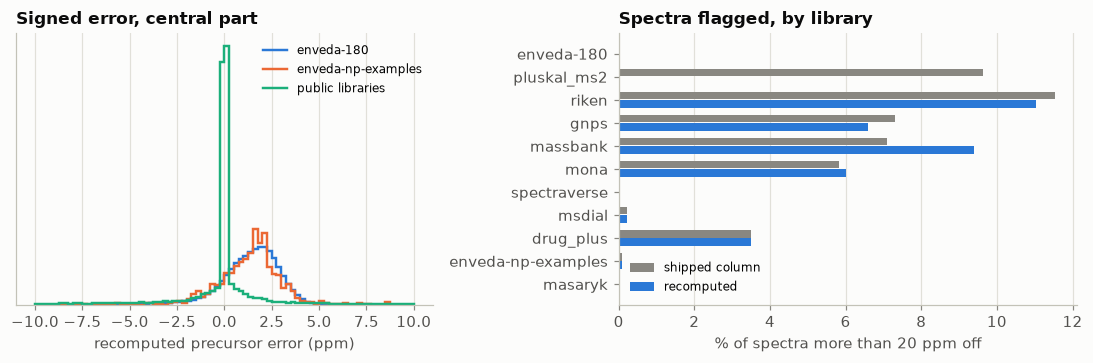

over 20 ppm: 119,514 spectra by the shipped column, 68,123 recomputed
flagged by the shipped column but consistent when recomputed: 55,645
shipped column missing: 4,286; recomputed missing: 15


ingest_lib,adduct,adduct_orig,len
str,str,str,u32
"""pluskal_ms2""","""[M+CH2O2-H]-""","""[M+CH2O2]-""","50,785"
"""riken""","""[M+H]+""","""[M+H]+""","2,073"
"""gnps""","""[M+CH2O2-H]-""","""[M+CH2O2]-""","1,675"
"""riken""","""[M+Na]+""","""[M+Na]+""",918


In [21]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1, 1.1]})
edges = np.linspace(-10, 10, 81)
for group in GROUPS:
    values = meta.filter(pl.col("group") == group)["ppm_error"].drop_nulls().to_numpy()
    density, _ = np.histogram(values, bins=edges, density=True)
    left.stairs(density, edges, color=GROUP_COLOURS[group], linewidth=1.6, label=group)
left.set_xlabel("recomputed precursor error (ppm)")
left.set_yticks([])
left.set_title("Signed error, central part")
left.legend(fontsize=8)

rows = error_by_library.sort("spectra")
y = np.arange(rows.height)
right.barh(y + 0.19, rows[f"% over {PPM_TOLERANCE:g} ppm, shipped"], height=0.34, color=GREY, label="shipped column")
right.barh(y - 0.19, rows[f"% over {PPM_TOLERANCE:g} ppm, recomputed"], height=0.34, color=BLUE, label="recomputed")
right.set_yticks(y, rows["ingest_lib"])
right.set_xlabel(f"% of spectra more than {PPM_TOLERANCE:g} ppm off")
right.set_title("Spectra flagged, by library")
right.legend(fontsize=8)
right.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

flagged_shipped = meta.filter(shipped_bad).height
flagged_ours = meta.filter(ours_bad).height
rescued = meta.filter(shipped_bad & ~ours_bad).height
print(f"over {PPM_TOLERANCE:g} ppm: {flagged_shipped:,} spectra by the shipped column, {flagged_ours:,} recomputed")
print(f"flagged by the shipped column but consistent when recomputed: {rescued:,}")
print(f"shipped column missing: {meta['precursor_error_ppm'].null_count():,}; recomputed missing: {meta['ppm_error'].null_count():,}")
meta.filter(shipped_bad & ~ours_bad).group_by("ingest_lib", "adduct", "adduct_orig").len().sort("len", descending=True).head(4)

What the recomputation shows:

- **The shipped column raises about 56,000 false alarms.** About 52,000 are formate adducts in
  `pluskal_ms2` and `gnps`. Those libraries wrote the adduct as `[M+CH2O2]-`, which the dataset
  normalised to the correct `[M+CH2O2-H]-`. The precursor m/z agrees with the normalised adduct
  to a fraction of a ppm, but the shipped error was evidently computed against the original
  notation, which is one hydrogen (1.007 Da) heavier. That reads as an error of 2,000 to 3,000
  ppm on spectra that are fine. Filtering on the shipped column would have thrown away a tenth
  of `pluskal_ms2`.
- **The shipped column is unsigned** everywhere except `enveda-np-examples`, and it is missing
  for 4,286 spectra that we can compute.
- **Some libraries store a calculated precursor, not a measured one.** In `pluskal_ms2`,
  `msdial` and `drug_plus` over 94% of spectra are within 0.3 ppm of the formula value, far
  tighter than any instrument measures. For those libraries the error says nothing about the
  measurement, only that the label is self-consistent.
- **The two Enveda libraries share a calibration offset** of about +1.9 ppm in positive mode.
  Every `enveda-180` spectrum is within 6 ppm, and all but one natural-product example within
  12 ppm. That is what one well-calibrated instrument
  looks like, and what we should expect from the test set.
- **Real label problems remain**, concentrated in `riken`, `massbank`, `gnps` and `mona`. The
  next table looks at spectra more than 50 ppm out and asks how far, in Da, the precursor is
  from where the label puts it.

In [22]:
far_off = (
    meta.filter(pl.col("ppm_error").abs() > 50)
    .with_columns(((pl.col("precursor_mz") - pl.col("expected_mz")) * pl.col("charge").abs()).round(2).alias("gap in Da"))
)
print(f"{far_off.height:,} spectra ({far_off.height / meta.height:.1%}) are more than 50 ppm from their label")
(
    far_off.group_by("gap in Da")
    .agg(pl.len().alias("spectra"), pl.col("ingest_lib").mode().first().alias("mostly from"),
         pl.col("adduct").mode().first().alias("most common label"))
    .sort("spectra", descending=True).head(6)
)

51,673 spectra (2.0%) are more than 50 ppm from their label


gap in Da,spectra,mostly from,most common label
f64,u32,str,str
-1.010,"3,082","""gnps""","""[M+NH4]+"""
-0.050,"1,185","""riken""","""[M-H]-"""
21.980,"1,174","""gnps""","""[M+H]+"""
-0.060,"1,142","""riken""","""[M-H]-"""
-0.070,"1,085","""riken""","""[M+H]+"""
-0.090,"1,079","""riken""","""[M+H]+"""


The commonest gaps are chemically meaningful, which tells us these are mislabelled adducts
rather than random noise. A gap of 21.98 Da is sodium minus hydrogen: the spectrum is labelled
`[M+H]+` but the ion was `[M+Na]+`. A gap of -1.01 Da is one hydrogen. The many small gaps of a
few hundredths of a Da come from instruments that report masses to two decimals.

We keep `ppm_error` as a column in the cleaned data instead of filtering on it, so the baseline
strand can test what a filter does to accuracy. About 2.7% of spectra are more than 20 ppm out.

### 3.7 Collision energies

In [23]:
units = (
    meta.group_by("ingest_lib", "collision_energy_orig_units").len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("ingest_lib") * 100).round(0).alias("share"))
    .pivot(on="collision_energy_orig_units", index="ingest_lib", values="share")
    .fill_null(0).sort("ingest_lib")
)
print("collision-energy units, % of each library's spectra")
units

collision-energy units, % of each library's spectra


ingest_lib,unknown,eV,NCE,V
str,f64,f64,f64,f64
"""drug_plus""",100.000,0.000,0.000,0.000
"""enveda-180""",0.000,100.000,0.000,0.000
"""enveda-np-examples""",0.000,100.000,0.000,0.000
"""gnps""",100.000,0.000,0.000,0.000
"""masaryk""",100.000,0.000,0.000,0.000
"""massbank""",2.000,41.000,39.000,18.000
"""mona""",16.000,18.000,55.000,11.000
"""msdial""",32.000,18.000,22.000,27.000
"""pluskal_ms2""",0.000,0.000,100.000,0.000


In [24]:
settings = (
    meta.filter(pl.col("group") != "public libraries")
    .group_by("group", "collision_energy_orig").len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("group") * 100).alias("% of group"))
    .sort("group", "len", descending=[False, True])
    .group_by("group", maintain_order=True).head(6)
)
settings.select("group", "collision_energy_orig", "% of group")

group,collision_energy_orig,% of group
str,str,f64
"""enveda-180""","""40""",21.165
"""enveda-180""","""20,40,60""",20.812
"""enveda-180""","""60""",19.867
"""enveda-180""","""20""",15.011
"""enveda-180""","""-40""",7.217
"""enveda-180""","""-60""",6.088
"""enveda-np-examples""","""40""",17.990
"""enveda-np-examples""","""20;50""",17.652
"""enveda-np-examples""","""60""",16.892


- Only 54% of spectra give the collision energy in eV. 31% use NCE, a Thermo scale that is
  relative to the precursor mass, and 13% give no unit. The numbers are not comparable across
  units, so collision energy is usable as a model input only within one instrument family.
- The two Enveda libraries were acquired differently. `enveda-180` uses 20, 40, 60 eV and the
  three combined. `enveda-np-examples` uses other settings, such as 20 and 50 combined, or four
  energies combined. If the hidden test set follows the natural-product protocol, a model must
  not depend on the exact energies it saw in training.

### 3.8 Peaks

`num_peaks` is available for every spectrum, so the first figure uses the full data.

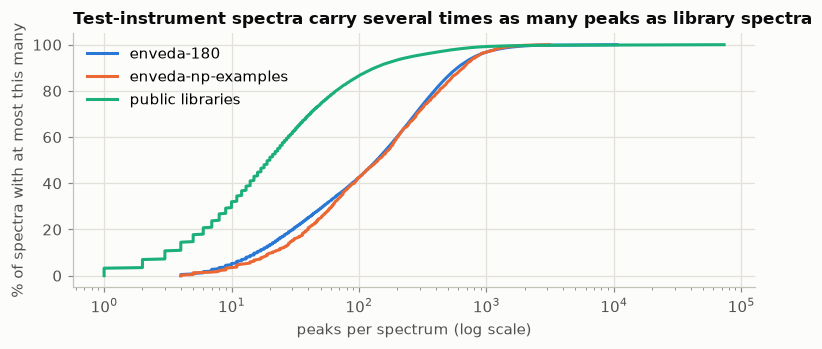

401,806,233 peaks in total


ingest_lib,median,95th percentile,max,% with under 3 peaks,million peaks
str,i64,i64,i64,f64,f64
"""enveda-180""",138,823,"10,620",0.000,284.414
"""gnps""",46,674,"73,318",1.394,48.257
"""mona""",57,878,"56,400",1.016,27.129
"""pluskal_ms2""",21,118,733,2.552,18.502
"""riken""",9,118,"22,439",19.131,12.731
"""spectraverse""",47,402,"4,096",0.966,5.786
"""massbank""",11,93,"1,418",10.032,2.640
"""msdial""",11,135,"8,554",10.845,1.752
"""enveda-np-examples""",142,847,"3,121",0.000,0.304


In [25]:
fig, ax = plt.subplots(figsize=(8, 3))
probabilities = np.linspace(0, 1, 401)
for group in GROUPS:
    values = meta.filter(pl.col("group") == group)["num_peaks"].to_numpy()
    ax.plot(np.quantile(values, probabilities), probabilities * 100, color=GROUP_COLOURS[group], label=group)
ax.set_xscale("log")
ax.set_xlabel("peaks per spectrum (log scale)")
ax.set_ylabel("% of spectra with at most this many")
ax.set_title("Test-instrument spectra carry several times as many peaks as library spectra")
ax.legend()
plt.show()

print(f"{meta['num_peaks'].sum():,} peaks in total")
(
    meta.group_by("ingest_lib")
    .agg(pl.col("num_peaks").quantile(0.5, "nearest").cast(pl.Int64).alias("median"),
         pl.col("num_peaks").quantile(0.95, "nearest").cast(pl.Int64).alias("95th percentile"),
         pl.col("num_peaks").max().alias("max"), (pl.col("num_peaks") < 3).mean().mul(100).alias("% with under 3 peaks"),
         (pl.col("num_peaks").sum() / 1e6).alias("million peaks"))
    .sort("million peaks", descending=True)
)

- The training set holds about 400 million peaks, and `enveda-180` alone holds 71% of them. Its
  spectra have a median of 138 peaks against 9 to 57 in the public libraries (the small
  `drug_plus` library, at 108, is the exception).
- Peak count per spectrum spans five orders of magnitude, from 1 to 73,318. The largest are
  `gnps` and `mona` spectra that were never reduced to peaks (raw profile data). A transformer's
  attention cost grows with the square of this number, so it has to be capped.
- 3.9% of spectra have fewer than three peaks, two thirds of them in `riken`.
  Such a spectrum cannot identify a molecule.

Are these extra timsTOF peaks signal or noise? That needs the peak lists themselves. We load
them for a hash-chosen sample of molecules, keeping every spectrum of each sampled molecule, and
for all 1,184 natural-product example spectra.

In [26]:
sample_share = min(1.0, PEAK_SAMPLE_FRACTION / SUBSAMPLE)
molecule_keys = molecules["inchikey14"]
sample_keys = molecule_keys.filter(stable_uniform(molecule_keys, "peak-sample") < sample_share)
# The natural-product examples are few and matter most, so all of their spectra are loaded as well.
in_sample = pl.col("inchikey14").is_in(sample_keys.implode()) | (pl.col("ingest_lib") == "enveda-np-examples")

started = time.perf_counter()
sample = (
    pl.scan_parquet(TRAIN, row_index_name="row_id")
    .filter(in_sample)
    .select("row_id", *PEAK_COLUMNS, "collision_energy_ev")
    .collect()
    .join(meta, on="row_id", how="inner")
    .sort("row_id")
)
print(f"{sample.height:,} spectra of {sample['inchikey14'].n_unique():,} molecules, {sample['num_peaks'].sum():,} peaks, "
      f"loaded in {time.perf_counter() - started:.0f} s")

# One row per peak. Only numbers are carried, to keep this large table small: the heaviest fragment
# the precursor allows, and the peak itself. A doubly charged ion can shed a charge and leave a
# fragment with a higher m/z than its precursor, so the limit is on mass: m/z times charge.
peaks = (
    sample.select(
        "row_id",
        (pl.col("precursor_mz") * pl.col("charge").abs() + PRECURSOR_WINDOW).cast(pl.Float32).alias("mz_limit"),
        pl.col("ms2_mzs").alias("mz"),
        pl.col("ms2_normalized_intensities").cast(pl.List(pl.Float32)).alias("intensity"),
    )
    .explode("mz", "intensity")
)
sample_labels = sample.select("row_id", "ingest_lib", "group")

105,307 spectra of 11,300 molecules, 16,506,693 peaks, loaded in 25 s


In [27]:
# Basic health checks on the peak lists.
checks = sample.select(
    (pl.col("ms2_normalized_intensities").list.max() == 1.0).mean().alias("tallest peak is exactly 1"),
    (pl.col("ms2_normalized_intensities").list.min() > 0).mean().alias("all intensities positive"),
    pl.col("ms2_mzs").list.eval((pl.element().diff() < 0).any()).list.first().not_().mean().alias("m/z ascending"),
    (pl.col("ms2_mzs").list.len() == pl.col("ms2_normalized_intensities").list.len()).mean().alias("lists the same length"),
)
checks.unpivot(variable_name="check", value_name="share of sampled spectra")

check,share of sampled spectra
str,f64
"""tallest peak is exactly 1""",1.000
"""all intensities positive""",1.000
"""m/z ascending""",1.000
"""lists the same length""",1.000


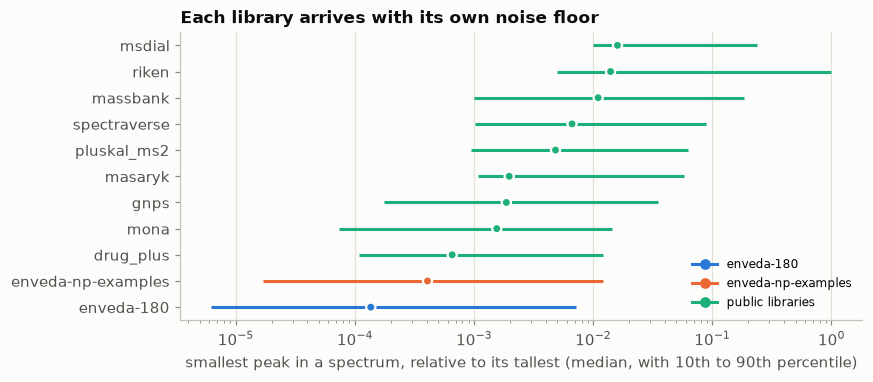

ingest_lib,peaks in sample,% under 0.1%,% under 0.5%,% under 1%,% above precursor
str,u32,f64,f64,f64,f64
"""enveda-180""","11,428,586",74.892,88.302,91.775,0.000
"""enveda-np-examples""","303,775",46.169,72.013,80.303,0.000
"""drug_plus""","11,728",20.865,50.102,62.091,0.060
"""mona""","1,126,027",40.510,58.315,64.044,6.087
"""gnps""","1,919,233",30.787,51.113,58.053,14.625
"""masaryk""",171,0.000,23.977,35.673,0.000
"""pluskal_ms2""","738,349",5.573,34.311,51.113,0.022
"""spectraverse""","217,656",0.000,30.698,45.670,0.303
"""massbank""","98,496",0.000,16.503,28.669,0.574


In [28]:
# Count per spectrum first, then add up per library.
above_limit = pl.col("mz") > pl.col("mz_limit")
spectrum_peaks = (
    peaks.lazy().group_by("row_id")
    .agg(pl.len().alias("peaks"),
         pl.col("intensity").min().alias("smallest"),
         (pl.col("intensity") < 0.001).sum().alias("under 0.1%"),
         (pl.col("intensity") < MIN_REL_INTENSITY).sum().alias("under floor"),
         (pl.col("intensity") < 0.01).sum().alias("under 1%"),
         above_limit.sum().alias("above"))
    .collect()
    .join(sample_labels, on="row_id")
)


def share_of_peaks(column: str) -> pl.Expr:
    return pl.col(column).sum() / pl.col("peaks").sum() * 100


peak_table = (
    spectrum_peaks.group_by("ingest_lib")
    .agg(pl.col("group").first(), pl.col("peaks").sum().alias("peaks in sample"),
         share_of_peaks("under 0.1%").alias("% under 0.1%"),
         share_of_peaks("under floor").alias(f"% under {MIN_REL_INTENSITY:.1%}"),
         share_of_peaks("under 1%").alias("% under 1%"),
         share_of_peaks("above").alias("% above precursor"),
         pl.col("smallest").quantile(0.1).alias("p10"), pl.col("smallest").median().alias("median"),
         pl.col("smallest").quantile(0.9).alias("p90"))
    .sort("median")
)

fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(peak_table.height)
ax.hlines(y, peak_table["p10"], peak_table["p90"], color=[GROUP_COLOURS[g] for g in peak_table["group"]], linewidth=2)
ax.scatter(peak_table["median"], y, s=36, color=[GROUP_COLOURS[g] for g in peak_table["group"]],
           edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.set_yticks(y, peak_table["ingest_lib"])
ax.set_xscale("log")
ax.set_xlabel("smallest peak in a spectrum, relative to its tallest (median, with 10th to 90th percentile)")
ax.set_title("Each library arrives with its own noise floor")
ax.legend(handles=[plt.Line2D([], [], color=c, marker="o", linewidth=2) for c in GROUP_COLOURS.values()],
          labels=GROUPS, fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()
peak_table.select("ingest_lib", "peaks in sample", "% under 0.1%", f"% under {MIN_REL_INTENSITY:.1%}",
                  "% under 1%", "% above precursor")

Every sampled spectrum is well formed: intensities are scaled to a tallest peak of 1, all
positive, with m/z ascending. The content differs sharply by library:

- **The libraries were cut at different noise floors.** `msdial` and `riken` were cut off by their
  curators at 1% and 0.5% of the tallest peak, `massbank` and `spectraverse` at 0.1%. The Enveda
  spectra were not cut at all: three quarters of `enveda-180` peaks are below 0.1%. That answers
  the question above. Most of the extra timsTOF peaks are tiny, at a level the public libraries'
  curators removed as noise.
- This matters for learning. The noise floor identifies the source library, and the library
  predicts the kind of molecule. A network could learn "many tiny peaks means a synthetic
  Enveda molecule" without reading any chemistry. Section 5 applies one floor to every spectrum
  to remove that shortcut.
- **Peaks above the precursor.** A fragment cannot weigh more than the ion it came from, apart
  from the precursor's own isotope peaks one or two Da above. The Enveda spectra respect this.
  In `gnps` about one peak in seven sits above the precursor, and in `mona` and `riken` about
  one in twenty, which points to contamination or a wrong precursor. Section 5 removes them.

### 3.9 What a spectrum looks like

The plot shows one molecule measured twice: on the test instrument (upward) and in a public
library (downward). Mirror plots like this are the standard way to compare two spectra.

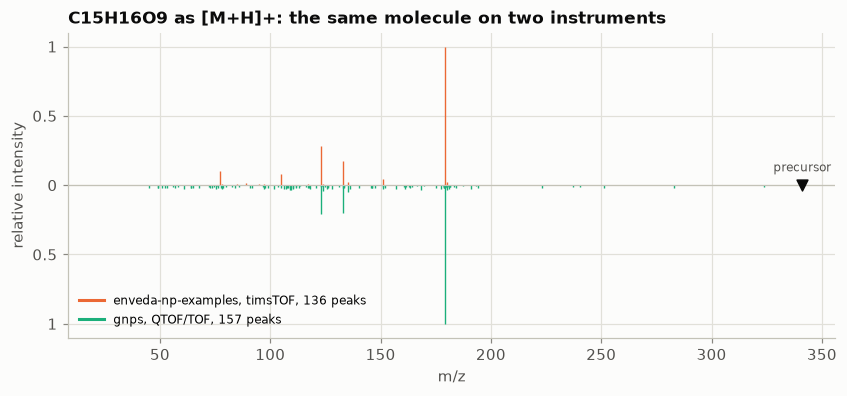

In [29]:
def pick_example(spectra: pl.DataFrame) -> tuple[dict, dict | None]:
    """A timsTOF spectrum and, if one exists, a library spectrum of the same molecule and adduct."""
    proton = spectra.filter((pl.col("adduct") == "[M+H]+") & (pl.col("num_peaks") >= 10))
    tims = proton.filter(pl.col("instrument_family") == "timsTOF")
    library = proton.filter(pl.col("instrument_family") != "timsTOF")
    paired = tims.join(library, on="inchikey14", how="semi")
    pool = paired if paired.height else tims if tims.height else spectra
    # Prefer a natural-product example, then a spectrum of typical size (about 150 peaks).
    first = pool.sort((pl.col("ingest_lib") != "enveda-np-examples"), (pl.col("num_peaks") - 150).abs(),
                      "row_id").row(0, named=True)
    partner = library.filter(pl.col("inchikey14") == first["inchikey14"]).sort(
        (pl.col("num_peaks") - 150).abs(), "row_id")
    return first, (partner.row(0, named=True) if partner.height else None)


def draw_spectrum(ax, spectrum: dict, colour: str, direction: int = 1, mz="ms2_mzs", intensity="ms2_normalized_intensities"):
    ax.vlines(spectrum[mz], 0, direction * np.asarray(spectrum[intensity]), color=colour, linewidth=0.9)


upper, lower = pick_example(sample)
fig, ax = plt.subplots(figsize=(9, 3.6))
draw_spectrum(ax, upper, GROUP_COLOURS[upper["group"]])
labels = [f"{upper['ingest_lib']}, {upper['instrument_family']}, {upper['num_peaks']} peaks"]
handles = [plt.Line2D([], [], color=GROUP_COLOURS[upper["group"]])]
if lower is not None:
    draw_spectrum(ax, lower, GROUP_COLOURS[lower["group"]], direction=-1)
    labels.append(f"{lower['ingest_lib']}, {lower['instrument_family']}, {lower['num_peaks']} peaks")
    handles.append(plt.Line2D([], [], color=GROUP_COLOURS[lower["group"]]))
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
ax.scatter([upper["precursor_mz"]], [0], marker="v", s=50, color=INK, zorder=3)
ax.annotate("precursor", (upper["precursor_mz"], 0), xytext=(0, 9), textcoords="offset points",
            ha="center", fontsize=8, color=INK_SOFT)
ax.set_xlim(max(0, min(upper["ms2_mzs"]) - 15), upper["precursor_mz"] + 15)
ax.set_xlabel("m/z")
ax.set_ylabel("relative intensity")
ax.set_yticks([-1, -0.5, 0, 0.5, 1], ["1", "0.5", "0", "0.5", "1"])
ax.set_title(f"{upper['molecular_formula']} as {upper['adduct']}: the same molecule on two instruments")
ax.legend(handles, labels, fontsize=8, loc="lower left")
plt.show()

The same fragments appear at the same masses on both instruments. That shared pattern is what
library matching and the neural models both rely on. The relative heights differ, because the
instruments and collision energies differ. Both spectra also carry over a hundred small peaks
along the baseline, most of them too small to see at this scale. The example is the natural-product spectrum closest to a typical
size that has a library partner. It was not picked for how well the two agree.

### 3.10 Is the training data like the test data?

The hidden test set is, in Enveda's words, about 400 "real or potential natural molecules and
their analogs", measured on Enveda's platform. Three parts of the training data could stand in
for it. The comparison below is per molecule.

In [30]:
formula = pl.col("molecular_formula")
ELEMENTS = ["N", "S", "F", "Cl", "Br", "P"]
group_molecules = meta.unique(subset=["group", "inchikey14"]).select("group", "inchikey14", "molecular_formula", "mono_mass")
chemistry = (
    group_molecules.group_by("group")
    .agg(
        pl.len().alias("molecules"),
        pl.col("mono_mass").quantile(0.01).alias("mass, 1st percentile"),
        pl.col("mono_mass").median().alias("mass, median"),
        pl.col("mono_mass").quantile(0.99).alias("mass, 99th percentile"),
        # An element symbol followed by a digit, a capital, a charge sign or the end of the formula.
        *[formula.str.contains(element + r"([0-9A-Z+\-]|$)").mean().mul(100).alias(f"% with {element}") for element in ELEMENTS],
        formula.str.contains(r"(F|Cl|Br|I)([0-9A-Z+\-]|$)").mean().mul(100).alias("% with a halogen"),
    )
    .sort("molecules", descending=True)
)
chemistry

group,molecules,"mass, 1st percentile","mass, median","mass, 99th percentile",% with N,% with S,% with F,% with Cl,% with Br,% with P,% with a halogen
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""enveda-180""","182,941",250.132,330.115,418.120,99.961,28.304,23.005,11.817,3.442,0.000,35.496
"""public libraries""","95,157",140.059,349.126,"1,125.659",78.801,20.428,10.315,8.938,2.403,5.601,20.371
"""enveda-np-examples""",250,138.043,354.194,"1,029.602",47.200,3.600,0.400,4.400,0.000,0.800,5.200


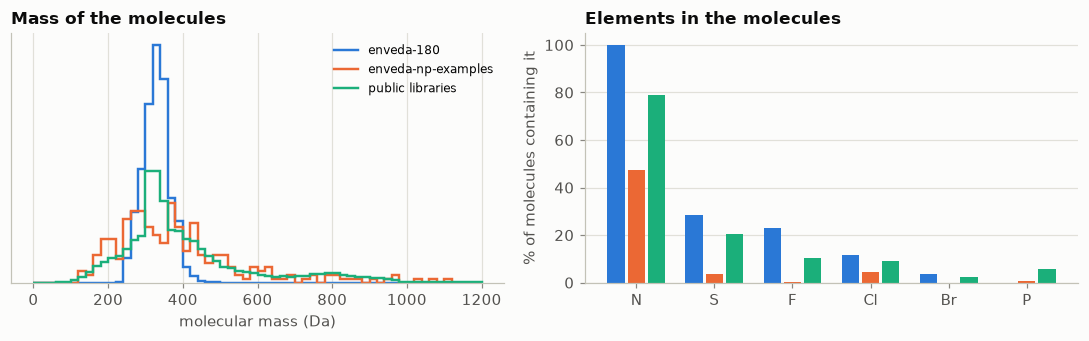

In [31]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.2))
edges = np.arange(0, 1201, 20)
for group in GROUPS:
    values = group_molecules.filter(pl.col("group") == group)["mono_mass"].drop_nulls().to_numpy()
    density, _ = np.histogram(values, bins=edges, density=True)
    left.stairs(density, edges, color=GROUP_COLOURS[group], linewidth=1.6, label=group)
left.set_xlabel("molecular mass (Da)")
left.set_yticks([])
left.set_title("Mass of the molecules")
left.legend(fontsize=8)

width = 0.26
for k, group in enumerate(GROUPS):
    row = chemistry.filter(pl.col("group") == group)
    values = [row[f"% with {element}"][0] if row.height else 0 for element in ELEMENTS]
    right.bar(np.arange(len(ELEMENTS)) + (k - 1) * width, values, width=width - 0.04, color=GROUP_COLOURS[group], label=group)
right.set_xticks(range(len(ELEMENTS)), ELEMENTS)
right.set_ylabel("% of molecules containing it")
right.set_title("Elements in the molecules")
right.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

`enveda-180`, the bulk of the test-instrument data, is not like natural products:

- **Mass.** 99% of its molecules weigh between 250 and 420 Da, a band typical of a library built
  for drug screening. The natural-product examples run from about 140 to over 1,000 Da.
- **Elements.** Every `enveda-180` molecule but a handful contains nitrogen, 28% contain sulphur
  and 35% a halogen. Among the natural-product examples 47% contain nitrogen and 5% a halogen.
  Halogens are common in synthetic chemistry and rare in nature.

So the training data splits into two halves that are each wrong in a different way. The public
libraries cover natural-product chemistry but come from other instruments. `enveda-180` comes
from the right instrument but covers synthetic chemistry. Only the 250 molecules of
`enveda-np-examples` are right on both counts. Three decisions follow, and section 7 implements
them:

1. All 250 natural-product examples are held out for validation and testing. They are too few
   to matter for training and too valuable to spend on it.
2. Scores on held-out `enveda-180` molecules are reported separately, because they measure
   performance on easier, more uniform chemistry than the test set.
3. A model trained only on timsTOF data would see almost no natural products. This is the
   argument for training on all instruments, and it is the first thing the neural strands
   should test.

## 4. How this dataset compares with the alternatives

The brief asks us to show that no more suitable data source exists. We need MS/MS spectra
labelled with structures, as many as possible, including the test instrument. The candidates:

| Source | Labelled spectra | Molecules | Access | Verdict |
| --- | --- | --- | --- | --- |
| **CASMI26 training set** (this project) | 2,539,608 | 275,810 | Kaggle, CC BY-NC 4.0 | Chosen. The largest open labelled set we found, and the only one with timsTOF data. |
| [MassSpecGym](https://arxiv.org/abs/2410.23326) | 231 thousand | 29 thousand | Open, MIT | A tenth of the size. Two adducts only, `[M+H]+` and `[M+Na]+`, on Orbitrap and QTOF. Its split design is the standard we compare ours with in section 7.5. |
| GNPS libraries | 322 thousand in May 2024, of which 104 thousand high quality | 16 thousand | Open | Already inside CASMI26 as `gnps`. |
| MoNA | 98 thousand, of which 62 thousand high quality | 10 thousand | Open | Already inside as `mona`. |
| MassBank | 62 thousand, of which 58 thousand high quality | 4 thousand | Open | Already inside as `massbank`. |
| [NIST 2023 tandem library](https://www.nist.gov/programs-projects/nist23-updates-nist-tandem-and-electron-ionization-spectral-libraries) | 2.4 million | 51,501 | Sold through distributors | Comparable in spectra, a fifth of the molecules, and not free. The MassSpecGym authors state that NIST libraries "are not available for machine learning due to licensing restrictions". |
| [DreaMS Atlas](https://github.com/pluskal-lab/DreaMS), mined from the MassIVE/GNPS repository | 201 million, unlabelled | none | Open | No structure labels, so it cannot train or score a structure predictor directly. It is what self-supervised pre-training uses. |

The GNPS, MoNA and MassBank counts are those in Table 1 of the MassSpecGym paper, which
downloaded all three in May 2024. GNPS has grown since: its
[library page](https://external.gnps2.org/gnpslibrary) listed 2,914,713 spectra in March 2026.

Two conclusions. First, CASMI26 is not an alternative to the open libraries but a superset of
them: section 3.1 found GNPS, MoNA, MassBank and six more inside it, plus 1.15 million timsTOF
spectra that exist nowhere else in the open. Second, the only larger labelled source is
commercial, and the only larger open source has no labels.

**How this compares with data in a real setting.** The exploration above lets us be specific:

- *It is a real aggregate, with the defects of one.* Eleven sources, 82 spellings of the
  instrument, four collision-energy units, a mass-error column that is wrong for 56,000 rows, and
  a file sorted so that its first rows are unrepresentative. None of this was planted for a
  competition. It is what combining laboratories' data looks like.
- *It is labelled, and real spectra are not.* Enveda's announcement cites that in a typical
  study only about 10% of measured signals can be matched to a known molecule. A deployed model
  would mostly see spectra with no label, from one instrument, of molecules unlike its training
  set. The DreaMS Atlas shows the scale: 201 million public spectra, 80 times this dataset, with
  no labels.
- *The shift between training and deployment is visible here.* Section 3.10 showed training
  chemistry and test chemistry differ. In a real setting that gap is the normal case, and a
  validation set that ignores it reports numbers that deployment will not reproduce.

So a 1000-fold larger version of this problem is not hypothetical, and it would not be 1000
times more labelled spectra. It would be this labelled set plus a few billion unlabelled
spectra, which is why pre-training and transfer learning matter for the project's scaling
argument.

## 5. Cleaning

The exploration found three kinds of problem: spectra whose label contradicts itself, peaks that
are noise or cannot belong to the molecule, and copies of the same spectrum. This section turns
each into a rule, sets the thresholds from the data, and tests the result on the sample. Section
8 applies the same function to the whole file.

### 5.1 Choosing the noise floor and the peak cap

Section 3.8 showed that libraries were cut off at different relative intensities. One floor for
all spectra removes that difference. The question is where to put it. For each sampled spectrum
we count the peaks that survive a range of floors, and the share of the spectrum's total
intensity they carry.

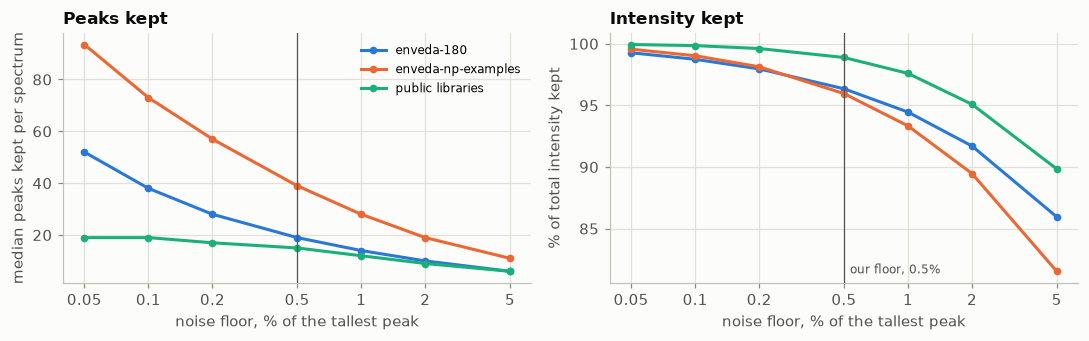

group,spectra in sample,median peaks,99th percentile,max,% over 256
str,u32,f64,f64,u32,f64
"""enveda-180""","46,504",19.000,164.000,"1,885",0.275
"""enveda-np-examples""","1,184",39.000,398.000,761,5.659
"""public libraries""","57,225",15.000,319.000,"30,440",1.456


In [32]:
floors_tried = sorted({0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, MIN_REL_INTENSITY})
per_spectrum = (
    peaks.lazy().filter(~above_limit)                     # peaks above the precursor go first
    .group_by("row_id")
    .agg(pl.col("intensity").sum().alias("total"),
         *[(pl.col("intensity") >= floor).sum().alias(f"kept_{floor}") for floor in floors_tried],
         *[pl.col("intensity").filter(pl.col("intensity") >= floor).sum().alias(f"sum_{floor}") for floor in floors_tried])
    .collect()
    .join(sample_labels, on="row_id")
)
floor_effect = per_spectrum.group_by("group").agg(
    *[pl.col(f"kept_{floor}").median().alias(f"kept_{floor}") for floor in floors_tried],
    *[(pl.col(f"sum_{floor}") / pl.col("total")).mean().mul(100).alias(f"sum_{floor}") for floor in floors_tried],
)

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
x = [floor * 100 for floor in floors_tried]
for group in GROUPS:
    row = floor_effect.filter(pl.col("group") == group)
    if row.height == 0:
        continue
    left.plot(x, [row[f"kept_{floor}"][0] for floor in floors_tried], marker="o", markersize=4,
              color=GROUP_COLOURS[group], label=group)
    right.plot(x, [row[f"sum_{floor}"][0] for floor in floors_tried], marker="o", markersize=4,
               color=GROUP_COLOURS[group], label=group)
for ax in (left, right):
    ax.set_xscale("log")
    ax.set_xticks(x, [f"{value:g}" for value in x])
    ax.minorticks_off()
    ax.axvline(MIN_REL_INTENSITY * 100, color=INK_SOFT, linewidth=0.8)
    ax.set_xlabel("noise floor, % of the tallest peak")
left.set_ylabel("median peaks kept per spectrum")
left.set_title("Peaks kept")
left.legend(fontsize=8)
right.set_ylabel("% of total intensity kept")
right.set_title("Intensity kept")
right.annotate(f"our floor, {MIN_REL_INTENSITY:.1%}", (MIN_REL_INTENSITY * 100, right.get_ylim()[0]),
               xytext=(4, 6), textcoords="offset points", fontsize=8, color=INK_SOFT)
plt.tight_layout()
plt.show()

# How often would a cap on the number of peaks bite, once the floor is applied?
at_floor = pl.col(f"kept_{MIN_REL_INTENSITY}")
per_spectrum.group_by("group").agg(
    pl.len().alias("spectra in sample"),
    at_floor.quantile(0.5, "nearest").alias("median peaks"), at_floor.quantile(0.99, "nearest").alias("99th percentile"),
    at_floor.max().alias("max"), (at_floor > MAX_PEAKS).mean().mul(100).alias(f"% over {MAX_PEAKS}"),
).sort("group")

- A floor of 0.5% of the tallest peak keeps over 95% of the intensity in every group while
  cutting a typical `enveda-180` spectrum from about 140 peaks to about 20. The public spectra
  barely change, because most were already cut at or near this level. After the floor, the three
  groups have comparable peak counts, which is the point.
- 0.5% is the level `riken` was already cut at, so it is the lowest floor that most of the data
  can share. Going to 1% would match `msdial` as well, but it removes a further 2 to 3% of the Enveda
  spectra's intensity.
- The natural-product examples keep the most peaks. Many of their spectra combine several
  collision energies, so they hold more genuine fragments. A cap of 256 peaks leaves most of them
  whole and still bounds the worst case, which was 73,318 peaks.

### 5.2 The rules

| Rule | Applies to | Why |
| --- | --- | --- |
| Adduct cannot be parsed | spectrum, dropped | No mass can be computed for it (section 3.4). |
| Ionisation mode contradicts the adduct's sign | spectrum, dropped | The label contradicts itself (section 3.4). |
| Precursor m/z outside 50 to 1,500 | spectrum, dropped | Data-entry errors and molecules far larger than the test set's (section 3.5). |
| Exact copy of an earlier spectrum of the same molecule and adduct | spectrum, dropped | The libraries overlap (section 3.2), and copies give some molecules extra weight. |
| Peak more than 2.5 Da above the precursor mass | peak, removed | A fragment cannot outweigh its precursor. 2.5 Da leaves room for isotope peaks (section 3.8). |
| Peak below 0.5% of the tallest peak | peak, removed | One noise floor for all libraries (section 5.1). |
| More than 256 peaks left | peaks, the 256 most intense kept | Bounds the cost of attention and of search (section 5.1). |
| No peak left | spectrum, dropped | Nothing to learn from. |
| Fewer than 3 peaks left | training spectrum, dropped | Too little to identify a molecule. Held-out query spectra are kept whatever their size, because the test set has to be answered as it comes. |

After the peak rules the intensities are rescaled so the tallest remaining peak is 1 again.
Precursor mass error is deliberately *not* a rule: `ppm_error` stays as a column so that the
effect of filtering on it can be measured.

The first three rules need only the non-peak columns, so their effect on the full data is known
already:

In [33]:
rule_counts = meta.select(
    pl.len().alias("all spectra"),
    pl.col("charge").is_null().sum().alias("adduct cannot be parsed"),
    (~pl.col("mode_matches_adduct")).sum().alias("mode contradicts adduct"),
    (~pl.col("precursor_in_range")).sum().alias("precursor m/z out of range"),
    (~pl.col("metadata_ok")).sum().alias("dropped by any of the three"),
)
rule_counts.unpivot(variable_name="rule", value_name="spectra").with_columns(
    (pl.col("spectra") / meta.height * 100).alias("% of spectra"))

rule,spectra,% of spectra
str,u32,f64
"""all spectra""","2,539,608",100.000
"""adduct cannot be parsed""",15,0.001
"""mode contradicts adduct""","6,087",0.240
"""precursor m/z out of range""","1,427",0.056
"""dropped by any of the three""","7,509",0.296


### 5.3 The cleaning function

`clean_peaks` applies the peak rules to a batch of spectra and bins the result (section 6). It
works by putting one peak per row, filtering, and collecting the rows back into lists. The same
function is used on the sample here, on the whole training file in section 8, and can be applied
to the test file when a submission is made.

In [34]:
def clean_peaks(spectra: pl.DataFrame) -> pl.DataFrame:
    """Clean and bin the peak lists of a batch of spectra.

    Needs the columns row_id, precursor_mz, charge, ms2_mzs and ms2_normalized_intensities.
    Returns one row per spectrum that keeps at least one peak: the cleaned peak list (mzs,
    intensities), its binned form (bins, bin_intensities) and n_peaks.
    """
    kept = (
        spectra.lazy()
        .select(
            "row_id",
            # The heaviest fragment a precursor can give. A multiply charged ion can lose charge,
            # so the bound is on mass, which is m/z times charge.
            (pl.col("precursor_mz") * pl.col("charge").abs() + PRECURSOR_WINDOW)
            .clip(upper_bound=MAX_FRAGMENT_MZ).alias("mz_limit"),
            pl.col("ms2_mzs").alias("mz"),
            pl.col("ms2_normalized_intensities").alias("intensity"),
        )
        .explode("mz", "intensity")                                    # one peak per row
        .filter((pl.col("intensity") >= MIN_REL_INTENSITY) & (pl.col("mz") <= pl.col("mz_limit")))
        .filter(pl.col("intensity").rank("ordinal", descending=True).over("row_id") <= MAX_PEAKS)
        .with_columns(pl.col("intensity") / pl.col("intensity").max().over("row_id"))
    )
    peak_lists = kept.group_by("row_id", maintain_order=True).agg(
        pl.col("mz").alias("mzs"), pl.col("intensity").cast(pl.Float32).alias("intensities"))
    binned = (
        kept.with_columns((pl.col("mz") / BIN_WIDTH + 1e-9).floor().cast(pl.Int32).alias("bin"))
        .group_by("row_id", "bin").agg(pl.col("intensity").sum())      # peaks sharing a bin are added
        .sort("row_id", "bin")
        .with_columns(pl.col("intensity") / pl.col("intensity").max().over("row_id"))
        .group_by("row_id", maintain_order=True)
        .agg(pl.col("bin").alias("bins"), pl.col("intensity").cast(pl.Float32).alias("bin_intensities"))
    )
    return (
        peak_lists.join(binned, on="row_id")
        .with_columns(pl.col("mzs").list.len().cast(pl.Int32).alias("n_peaks"))
        .collect()
    )


CLEANING_INPUT = ["row_id", "precursor_mz", "charge", *PEAK_COLUMNS]
usable = sample.filter(pl.col("metadata_ok"))
started = time.perf_counter()
cleaned_sample = clean_peaks(usable.select(CLEANING_INPUT))
seconds = time.perf_counter() - started
print(f"cleaned {usable.height:,} spectra in {seconds:.1f} s ({usable.height / seconds:,.0f} spectra per second)")

after = usable.select("row_id", "group", "num_peaks").join(cleaned_sample.select("row_id", "n_peaks"), on="row_id", how="left")
after.group_by("group").agg(
    pl.len().alias("spectra"),
    pl.col("num_peaks").quantile(0.5, "nearest").cast(pl.Int64).alias("median peaks before"),
    pl.col("n_peaks").quantile(0.5, "nearest").cast(pl.Int64).alias("median peaks after"),
    (pl.col("n_peaks").sum() / pl.col("num_peaks").sum() * 100).alias("% of peaks kept"),
    (pl.col("n_peaks") == MAX_PEAKS).mean().mul(100).alias(f"% capped at {MAX_PEAKS}"),
    (pl.col("n_peaks").fill_null(0) < MIN_PEAKS_TRAIN).mean().mul(100).alias(f"% under {MIN_PEAKS_TRAIN} peaks"),
).sort("group")

cleaned 104,915 spectra in 1.3 s (81,953 spectra per second)


group,spectra,median peaks before,median peaks after,% of peaks kept,% capped at 256,% under 3 peaks
str,u32,i64,i64,f64,f64,f64
"""enveda-180""","46,504",137,19,11.503,0.280,0.402
"""enveda-np-examples""","1,184",142,39,25.971,5.828,0.084
"""public libraries""","57,227",19,15,36.635,1.441,8.288


The figure shows the test-instrument spectrum from section 3.9 before cleaning (upward) and
after (downward).

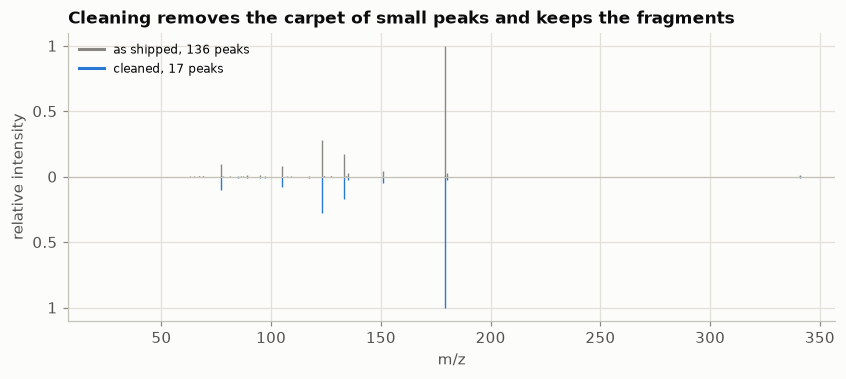

In [35]:
example_clean = cleaned_sample.filter(pl.col("row_id") == upper["row_id"])
fig, ax = plt.subplots(figsize=(9, 3.4))
draw_spectrum(ax, upper, GREY)
handles, labels = [plt.Line2D([], [], color=GREY)], [f"as shipped, {upper['num_peaks']} peaks"]
if example_clean.height:
    cleaned_row = example_clean.row(0, named=True)
    draw_spectrum(ax, cleaned_row, BLUE, direction=-1, mz="mzs", intensity="intensities")
    handles.append(plt.Line2D([], [], color=BLUE))
    labels.append(f"cleaned, {cleaned_row['n_peaks']} peaks")
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
ax.set_xlabel("m/z")
ax.set_ylabel("relative intensity")
ax.set_yticks([-1, -0.5, 0, 0.5, 1], ["1", "0.5", "0", "0.5", "1"])
ax.set_title("Cleaning removes the carpet of small peaks and keeps the fragments")
ax.legend(handles, labels, fontsize=8, loc="upper left")
plt.show()

### 5.4 Exact copies

Two spectra count as copies if they belong to the same molecule and adduct and have the same
number of peaks, the same sum of m/z values and the same sum of intensities. The sample holds
every spectrum of each hash-chosen molecule, so copies among those are counted correctly.

In [36]:
COPY_KEY = ["inchikey14", "adduct", "num_peaks", "mz_sum", "intensity_sum"]
copy_sums = [
    pl.col("ms2_mzs").list.sum().round(3).alias("mz_sum"),
    pl.col("ms2_normalized_intensities").list.sum().round(4).alias("intensity_sum"),
]
fingerprinted = usable.filter(pl.col("inchikey14").is_in(sample_keys.implode())).with_columns(copy_sums)
redundant = fingerprinted.filter(~pl.struct(COPY_KEY).is_first_distinct())
print(f"{redundant.height:,} of {fingerprinted.height:,} sampled spectra ({redundant.height / fingerprinted.height:.1%}) "
      f"are copies of an earlier spectrum")
(
    fingerprinted.filter(pl.struct(COPY_KEY).is_duplicated())
    .group_by(COPY_KEY).agg(pl.col("ingest_lib").unique().sort().str.join(" + ").alias("libraries holding the copies"))
    .group_by("libraries holding the copies").len().rename({"len": "sets of copies"})
    .sort("sets of copies", descending=True).head(6)
)

3,261 of 103,769 sampled spectra (3.1%) are copies of an earlier spectrum


libraries holding the copies,sets of copies
str,u32
"""gnps + mona""","1,145"
"""msdial + riken""","1,053"
"""gnps + pluskal_ms2""",691
"""pluskal_ms2""",201
"""gnps + massbank""",21
"""riken""",19


About 3% of spectra are exact copies, and nearly all of them are the same record held by two
libraries: `msdial` and `riken`, `gnps` and `mona`, `gnps` and `pluskal_ms2`. This is the overlap
seen in section 3.2, at the level of individual spectra. Section 8 keeps the first copy in file
order and drops the rest.

Finding copies is the one cleaning step that needs to compare spectra from different parts of
the file. Every other rule looks at one spectrum at a time. That difference matters at scale and
section 8 comes back to it.

## 6. Binning

The fingerprint MLP needs each spectrum as a vector of fixed length. The usual way is to cut the
m/z axis into bins of equal width and record the intensity in each. How wide should a bin be?
The data can answer that. The figure shows, for the cleaned sample, the gap between each peak
and the next peak in the same spectrum.

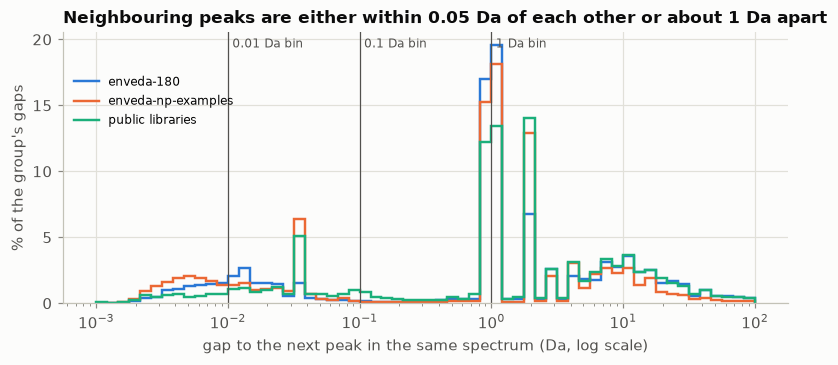

19.0% of gaps are under 0.05 Da, 5.1% are between 0.05 and 0.75 Da


In [37]:
clean_rows = cleaned_sample.select("row_id", pl.col("mzs").alias("mz")).explode("mz")
gaps = (
    clean_rows.with_columns((pl.col("mz") - pl.col("mz").shift(1)).over("row_id").alias("gap"))
    .filter(pl.col("gap") > 0)
    .select("row_id", "gap")
)
edges = np.logspace(-3, 2, 61)
fig, ax = plt.subplots(figsize=(8.5, 3.2))
for group in GROUPS:
    in_group = sample_labels.filter(pl.col("group") == group).select("row_id")
    values = gaps.join(in_group, on="row_id", how="semi")["gap"].to_numpy()
    if len(values):
        counts, _ = np.histogram(values, bins=edges)
        ax.stairs(counts / len(values) * 100, edges, color=GROUP_COLOURS[group], linewidth=1.6, label=group)
for width in (0.01, 0.1, 1.0):
    ax.axvline(width, color=INK_SOFT, linewidth=0.8)
    ax.annotate(f"{width:g} Da bin", xy=(width, 1), xycoords=("data", "axes fraction"), xytext=(3, -10),
                textcoords="offset points", fontsize=8, color=INK_SOFT)
ax.set_xscale("log")
ax.set_xlabel("gap to the next peak in the same spectrum (Da, log scale)")
ax.set_ylabel("% of the group's gaps")
ax.set_title("Neighbouring peaks are either within 0.05 Da of each other or about 1 Da apart")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0.0, 0.88))
plt.show()
print(f"{(gaps['gap'] < 0.05).mean():.1%} of gaps are under 0.05 Da, "
      f"{gaps['gap'].is_between(0.05, 0.75).mean():.1%} are between 0.05 and 0.75 Da")

The gaps fall into two clusters with little in between:

- **Under about 0.05 Da:** peaks that are in effect the same. Either one fragment was recorded
  more than once with slightly different masses, or two fragments share a nominal mass. The spike
  near 0.036 Da matches the mass difference between CH4 and O, a common pair of that kind.
- **About 1 Da and above:** different fragments, and isotope peaks.

A bin has to be wider than the first cluster, or one fragment is split over two bins and its
intensity is diluted. It has to be narrower than the second, or different fragments are added
together. **0.1 Da** sits in the nearly empty stretch between the clusters. A bin of 0.01 Da cuts
through the first cluster. A bin of 1 Da is at the edge of the second, and at m/z 200 it is 5,000
ppm wide, a thousand times coarser than these instruments measure. The public libraries fill the
stretch between the clusters more than the timsTOF data does, because some of their instruments
report masses to only one or two decimals.

The table confirms it with numbers, and adds the cost of each choice.

In [38]:
rows = []
for width in [1.0, 0.1, 0.01]:
    filled_bins, peaks_sharing = (
        clean_rows.lazy()
        .with_columns((pl.col("mz") / width + 1e-9).floor().cast(pl.Int32).alias("bin"))
        .group_by("row_id", "bin").len()                     # peaks in each filled bin
        .select(pl.len(), pl.col("len").filter(pl.col("len") > 1).sum().alias("sharing"))
        .collect().row(0)
    )
    n_bins = int(np.ceil(MAX_FRAGMENT_MZ / width))
    filled = filled_bins / cleaned_sample.height
    rows.append({
        "bin width (Da)": width,
        "vector length": n_bins,
        "filled bins per spectrum": filled,
        "% of peaks sharing a bin": peaks_sharing / clean_rows.height * 100,
        "dense, GB for this dataset": n_bins * 4 * N_ROWS / 1e9,
        "sparse, GB for this dataset": filled * 8 * N_ROWS / 1e9,
    })
pl.DataFrame(rows)

bin width (Da),vector length,filled bins per spectrum,% of peaks sharing a bin,"dense, GB for this dataset","sparse, GB for this dataset"
f64,i64,f64,f64,f64,f64
1.000,"1,503",23.353,37.076,15.268,0.474
0.100,"15,025",25.115,27.988,152.630,0.510
0.010,"150,250",29.039,5.746,"1,526.304",0.590


- At 0.1 Da about a quarter of the peaks share a bin with a neighbour. That is the first cluster
  being merged, as intended. At 0.01 Da most of those pairs stay split.
- Going from 0.1 Da to 1 Da merges roughly a further tenth of the peaks, and those are different
  fragments.

The last two columns are the scaling point. Stored *densely* as 32-bit numbers, the 0.1 Da
vectors for this dataset would take about 150 GB, and 1000 times the data about 150 TB. But a
cleaned spectrum fills only a few dozen of its 15,025 bins. Stored *sparsely*, as the list of
filled bins and their intensities, the same information is under 1 GB, and it grows with the
number of peaks, not with the length of the vector. So `clean_peaks` returns the sparse form
(`bins`, `bin_intensities`), and a model turns one batch at a time into a dense array just before
it needs it. Section 9 gives the function. A coarser grid is one integer division away:
`bins // 10` is the 1 Da binning.

In [39]:
# The peak-level tables are not needed again. Dropping them keeps memory use down for the rest of
# the notebook.
del sample, peaks, cleaned_sample, clean_rows, gaps

## 7. The validation split

Every model in the project is scored on the same held-out molecules. The split has to do three
things: keep the answers out of the training data, resemble the hidden test set as closely as
the data allows, and come out identical on every teammate's machine.

### 7.1 What we are imitating

From the competition description and section 2.3, the hidden test set is:

- about 400 molecules, each with a handful of timsTOF spectra and no dimers;
- natural products and their analogues;
- scored per molecule: 25 ranked guesses, and the score is the mean reciprocal rank of the first
  correct one (MRR@25), where correct means the same `inchikey14`;
- a hidden mix of three classes of molecule, which differ in how much is already known:

| Class | What is known about the molecule | How we simulate it | What a model may still use |
| --- | --- | --- | --- |
| 1 | It has spectra in public libraries | Hold out its timsTOF spectra only | Its library spectra and its structure |
| 2 | Its structure is in a database, but it has no public spectra | Hold out all of its spectra | Its structure, as one candidate among many |
| 3 | It is new | Hold out all of its spectra | Nothing. Its structure is withheld from the candidates |

We hold out two disjoint sets. **Validation** is for comparing methods and tuning them. **Test**
is looked at once, for the numbers in the final report, so that those numbers are not flattered
by the tuning.

### 7.2 Why the split is by molecule

Suppose we held out spectra at random instead. The next cell holds out 5% of the timsTOF
spectra and asks how many of them have a sibling, another spectrum of the same molecule, left in
the training data.

In [40]:
tims_spectra = meta.lazy().filter(pl.col("instrument_family") == "timsTOF").select("row_id", "inchikey14").collect()
held_at_random = tims_spectra.sample(fraction=0.05, seed=0)
remaining_molecules = (
    meta.select("row_id", "inchikey14").join(held_at_random.select("row_id"), on="row_id", how="anti")["inchikey14"].unique()
)
with_sibling = held_at_random["inchikey14"].is_in(remaining_molecules.implode()).mean()
print(f"random spectrum split: {with_sibling:.1%} of held-out spectra have the same molecule in the training data")

random spectrum split: 99.8% of held-out spectra have the same molecule in the training data


With a spectrum-level split, almost every "unseen" spectrum has the same molecule sitting in the
training data, often measured at a different collision energy in the same run. A model would
only need to match a spectrum to its sibling and read off the label. Its validation score would
measure look-up, and would say nothing about molecules that are actually new, which is what test
classes 2 and 3 are. Grouping by `inchikey14` puts all spectra of a molecule, and of its
stereoisomers, on the same side.

### 7.3 Building the split

Which molecules can play which class follows from what was measured for them. A molecule needs
at least one test-like spectrum (timsTOF, not a dimer) to be held out at all. To simulate class 1
it also needs at least one usable library spectrum.

In [41]:
is_tims = pl.col("instrument_family") == "timsTOF"
NP, LIB, ONLY = "natural-product examples", "enveda-180 with library spectra", "enveda-180 only"

split_table = (
    meta.lazy().filter(pl.col("metadata_ok"))            # spectra that pass the label rules of section 5.2
    .group_by("inchikey14")
    .agg(
        pl.len().alias("spectra"),
        (is_tims & ~pl.col("is_dimer")).sum().alias("query_spectra"),
        is_tims.sum().alias("timstof_spectra"),
        (~is_tims & (pl.col("num_peaks") >= MIN_PEAKS_TRAIN)).sum().alias("library_spectra"),
        (~is_tims).sum().alias("other_instrument_spectra"),
        (pl.col("ingest_lib") == "enveda-np-examples").any().alias("np_example"),
    )
    .sort("inchikey14")
    .collect()
)
can_query, has_library = pl.col("query_spectra") > 0, pl.col("library_spectra") > 0
split_table = split_table.with_columns(
    pl.when(can_query & has_library & pl.col("np_example")).then(pl.lit(NP))
    .when(can_query & has_library).then(pl.lit(LIB))
    .when(can_query & (pl.col("other_instrument_spectra") == 0)).then(pl.lit(ONLY))
    .alias("pool"),
    # Each molecule's place in the split is decided by a hash of its key and nothing else.
    stable_uniform(split_table["inchikey14"], SPLIT_SALT).alias("u"),
    stable_uniform(split_table["inchikey14"], "train-subset").alias("train_subset_rank"),
)
(
    split_table.group_by("pool").agg(pl.len().alias("molecules"), pl.col("query_spectra").sum())
    .with_columns(pl.col("pool").fill_null("no pool (stays in training)"))
    .sort("molecules")
)

pool,molecules,query_spectra
str,u32,u32
"""natural-product examples""",250,"1,184"
"""enveda-180 with library spectra""","2,257","10,660"
"""no pool (stays in training)""","95,682",4
"""enveda-180 only""","177,500","811,697"


The three pools, and how each is used:

- **Natural-product examples.** Measured on the test instrument and present in public libraries.
  The only test-like molecules we have (section 3.10), so all of them are held out as class 1,
  half to validation and half to test.
- **`enveda-180` with library spectra.** The same situation, for synthetic molecules. 40% go to
  validation and 40% to test as class 1, which brings class 1 up to a useful size.
- **`enveda-180` only.** Measured on the test instrument and nowhere else, so they have no
  library spectra to keep. Four slices of 0.56% each become class 2 and class 3 for validation
  and test, about 1,000 molecules per slice.

Molecules with no pool stay in training. Nearly all of them have no test-like spectrum. A
handful have one, but their only other spectra are too short to keep, so they fit no class.

A molecule's assignment depends only on the hash `u` of its own key. Nothing is sorted or
counted across molecules, so the rule gives the same answer on any machine, on any subsample,
and on a dataset 1000 times larger where the molecules would never be in one place at once.

In [42]:
u, slice_, share = pl.col("u"), TIMS_ONLY_SLICE, LIBRARY_HELD_OUT_FRACTION
pool = pl.col("pool")
split = (
    pl.when((pool == NP) & (u < NP_VAL_FRACTION)).then(pl.lit("val"))
    .when(pool == NP).then(pl.lit("test"))
    .when((pool == LIB) & (u < share)).then(pl.lit("val"))
    .when((pool == LIB) & (u < 2 * share)).then(pl.lit("test"))
    .when((pool == ONLY) & ((u < slice_) | u.is_between(2 * slice_, 3 * slice_, closed="left"))).then(pl.lit("val"))
    .when((pool == ONLY) & (u < 4 * slice_)).then(pl.lit("test"))
    .otherwise(pl.lit("train"))
)
split_table = split_table.with_columns(split.alias("split")).with_columns(
    pl.when(pl.col("split") == "train").then(None)
    .when(pool.is_in([NP, LIB])).then(1)
    .when(u < 2 * slice_).then(2)
    .otherwise(3).cast(pl.Int8).alias("sim_class")
)
# Class 3 molecules are "new": their structures must not be offered as candidates.
split_table = split_table.with_columns((pl.col("sim_class") != 3).fill_null(True).alias("in_candidates"))

held_out = split_table.filter(pl.col("split") != "train")
held_summary = (
    held_out.group_by("split", "sim_class", "pool")
    .agg(pl.len().alias("molecules"), pl.col("query_spectra").sum())
    .sort("split", "sim_class", "pool", descending=[True, False, False])
)
print(f"{held_out.height:,} of {split_table.height:,} molecules held out "
      f"({held_out.height / split_table.height:.1%})")
held_summary

5,996 of 275,689 molecules held out (2.2%)


split,sim_class,pool,molecules,query_spectra
str,i8,str,u32,u32
"""val""",1,"""enveda-180 with library spectra""",912,"4,254"
"""val""",1,"""natural-product examples""",126,604
"""val""",2,"""enveda-180 only""",961,"4,440"
"""val""",3,"""enveda-180 only""",999,"4,472"
"""test""",1,"""enveda-180 with library spectra""",887,"4,178"
"""test""",1,"""natural-product examples""",124,580
"""test""",2,"""enveda-180 only""",980,"4,474"
"""test""",3,"""enveda-180 only""","1,007","4,537"


Each spectrum now gets a role. `train` spectra may be trained on and searched as a library.
`query` spectra are the held-out questions. `excluded` spectra belong to held-out molecules but
are not test-like (their dimer spectra), so they are used for neither.

In [43]:
SPLIT = split_table.select("inchikey14", "pool", "split", "sim_class")


def assign_roles(spectra: pl.DataFrame) -> pl.DataFrame:
    """Join the split onto spectra and say what each spectrum may be used for."""
    held = pl.col("split").is_in(["val", "test"]).fill_null(False)
    tims = pl.col("instrument_family") == "timsTOF"
    return spectra.join(SPLIT, on="inchikey14", how="left").with_columns(
        pl.when(~held).then(pl.lit("train"))
        .when(tims & ~pl.col("is_dimer")).then(pl.lit("query"))
        .when(~tims & (pl.col("sim_class") == 1)).then(pl.lit("train"))     # library spectra of class 1
        .otherwise(pl.lit("excluded"))
        .alias("role")
    )


ROLE_COLUMNS = ["row_id", "inchikey14", "instrument_family", "is_dimer", "ionization_mode", "adduct",
                "precursor_mz", "num_peaks"]
roles = assign_roles(meta.lazy().filter(pl.col("metadata_ok")).select(ROLE_COLUMNS).collect())
roles.group_by("role").agg(pl.len().alias("spectra"), pl.col("inchikey14").n_unique().alias("molecules")).sort("spectra", descending=True)

role,spectra,molecules
str,u32,u32
"""train""","2,494,146","271,742"
"""query""","27,539","5,996"
"""excluded""","10,414","2,480"


### 7.4 Checks

The first cell asserts the properties the split exists to guarantee. If any fails, the notebook
stops.

In [44]:
in_training = pl.col("role") == "train"
queries = roles.filter(pl.col("role") == "query")

# No molecule is on two sides.
assert split_table["inchikey14"].is_unique().all()
# Classes 2 and 3: none of the molecule's spectra is left in training.
assert roles.filter(in_training & pl.col("sim_class").is_in([2, 3])).height == 0
# Class 1: only spectra from other instruments are left in training.
assert roles.filter(in_training & (pl.col("sim_class") == 1) & (pl.col("instrument_family") == "timsTOF")).height == 0
# Every held-out molecule has at least one query, and every class 1 molecule a library spectrum.
assert queries["inchikey14"].n_unique() == held_out.height
class_one_with_library = roles.filter(in_training & (pl.col("sim_class") == 1))["inchikey14"].n_unique()
assert class_one_with_library == held_out.filter(pl.col("sim_class") == 1).height
# Queries look like the test set: timsTOF and no dimers.
assert (queries["instrument_family"] == "timsTOF").all() and not queries["is_dimer"].any()
print("all split checks passed")

all split checks passed


The second check compares the validation queries with the local test file, which shows the
format of the hidden test set.

In [45]:
test_adduct_set = test["adduct"].unique()


def describe_queries(name: str, spectra: pl.DataFrame, molecule: str) -> dict:
    per_molecule = spectra.group_by(molecule).len()["len"]
    return {
        "set": name,
        "molecules": per_molecule.len(),
        "spectra": spectra.height,
        "spectra per molecule, median": per_molecule.median(),
        "spectra per molecule, max": per_molecule.max(),
        "% positive mode": (spectra["ionization_mode"] == "positive").mean() * 100,
        "% with an adduct found in the test file": spectra["adduct"].is_in(test_adduct_set.implode()).mean() * 100,
        "precursor m/z, median": spectra["precursor_mz"].median(),
    }


pl.DataFrame([
    describe_queries("local test file", test, "molecule_id"),
    *[describe_queries(f"validation queries, {name}", queries.filter((pl.col("split") == "val") & (pl.col("pool") == name)), "inchikey14")
      for name in (NP, LIB, ONLY)],
])

set,molecules,spectra,"spectra per molecule, median","spectra per molecule, max",% positive mode,% with an adduct found in the test file,"precursor m/z, median"
str,i64,i64,f64,i64,f64,f64,f64
"""local test file""",400,"1,213",3.000,9,81.369,100.000,329.198
"""validation queries, natural-product examples""",126,604,4.000,17,69.205,96.689,377.207
"""validation queries, enveda-180 with library spectra""",912,"4,254",4.000,12,69.676,100.000,325.155
"""validation queries, enveda-180 only""","1,960","8,912",4.000,19,74.742,99.933,333.139


The queries match the test file's format: all timsTOF, a few spectra per molecule, almost
entirely the same adducts, and a similar balance of ion modes (70 to 75% positive against 81%). The held-out `enveda-180` molecules match its
precursor masses too, as they should, since the local test file was drawn from that library.
The natural-product examples are heavier, which is the chemistry gap from section 3.10 again.

### 7.5 How new are the held-out molecules?

Splitting by `inchikey14` guarantees that a held-out molecule is not in the training data. It
does not guarantee that nothing *like* it is. The MassSpecGym authors make this point about the
common practice of splitting on the first InChIKey block: libraries are full of near-identical
molecules that differ by one small group, so a model can score well on "unseen" molecules by
recognising their close relatives. They instead keep every validation molecule at least 10 bond
edits away from every training molecule [(Bushuiev et al., 2024)](https://arxiv.org/abs/2410.23326).

We did not adopt their split, because the competition's own test set makes no such promise: it
contains "natural molecules and their analogs". But we should know how close our held-out
molecules are to the training set. The standard measure is the Tanimoto similarity of Morgan
fingerprints: 1 means the same set of local atom environments, and values above about 0.7 are
close analogues. For each held-out molecule we find its most similar training molecule, once
among training molecules measured on the test instrument and once among those from the public
libraries.

269,693 training molecules, 550 held-out molecules compared in 95 s


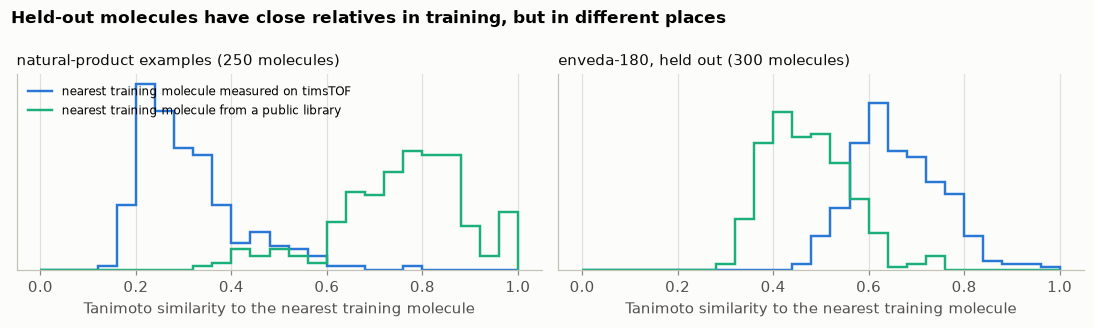

query group,molecules,"median, nearest on timsTOF",% with a timsTOF analogue (0.7+),"median, nearest in libraries",% with a library analogue (0.7+)
str,u32,f64,f64,f64,f64
"""enveda-180, held out""",300,0.654,32.667,0.465,2.333
"""natural-product examples""",250,0.281,0.400,0.775,72.800


In [46]:
# One structure per molecule: the first SMILES in file order.
structures = (
    pl.scan_parquet(TRAIN)
    .select("inchikey14", pl.col("normalized_smiles").alias("smiles"), "molecular_formula")
    .unique(subset="inchikey14", keep="first", maintain_order=True)
    .collect(engine="streaming")
    .join(split_table, on="inchikey14", how="inner")
    .join(FORMULAS, on="molecular_formula", how="left")
    .sort("inchikey14")
)

if RUN_SIMILARITY:
    from rdkit import Chem, DataStructs, RDLogger
    from rdkit.Chem import rdFingerprintGenerator

    RDLogger.DisableLog("rdApp.*")
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

    def packed_fingerprints(smiles: list[str], chunk: int = 5_000) -> np.ndarray:
        """Morgan fingerprints (radius 2, 2,048 bits), 64 bits to a number: one row of 32 per molecule."""
        parts = []
        for start in range(0, len(smiles), chunk):       # in chunks, so the parsed molecules are freed as we go
            parsed_ = [Chem.MolFromSmiles(s) for s in smiles[start:start + chunk]]
            parsed_ = [m if m is not None else Chem.Mol() for m in parsed_]
            bit_vectors = generator.GetFingerprints(parsed_, numThreads=os.cpu_count() or 1)
            parts.append(b"".join(DataStructs.BitVectToBinaryText(v) for v in bit_vectors))
        return np.frombuffer(b"".join(parts), dtype=np.uint64).reshape(len(smiles), -1)

    def tanimoto_to_all(query: np.ndarray, reference: np.ndarray, reference_bits: np.ndarray) -> np.ndarray:
        """Tanimoto similarity of one fingerprint to every reference fingerprint: shared bits / all bits."""
        shared = np.bitwise_count(reference & query).sum(axis=1, dtype=np.int32)
        return shared / np.maximum(reference_bits + int(np.bitwise_count(query).sum()) - shared, 1)

    started = time.perf_counter()
    reference_table = structures.filter(pl.col("split") == "train")
    reference = packed_fingerprints(reference_table["smiles"].to_list())
    reference_bits = np.bitwise_count(reference).sum(axis=1, dtype=np.int32)
    on_timstof = (reference_table["timstof_spectra"] > 0).to_numpy()
    in_library = (reference_table["other_instrument_spectra"] > 0).to_numpy()

    held_structures = structures.filter(pl.col("split") != "train").with_columns(
        pl.when(pl.col("pool") == NP).then(pl.lit(NP)).otherwise(pl.lit("enveda-180, held out")).alias("query group"))
    chosen = held_structures.sort("u").group_by("query group", maintain_order=True).head(
        max(N_SIMILARITY_QUERIES, held_structures.filter(pl.col("pool") == NP).height))
    nearest_tims, nearest_library = [], []
    for query in packed_fingerprints(chosen["smiles"].to_list()):
        similarity = tanimoto_to_all(query, reference, reference_bits)
        nearest_tims.append(similarity[on_timstof].max() if on_timstof.any() else 0.0)
        nearest_library.append(similarity[in_library].max() if in_library.any() else 0.0)
    chosen = chosen.with_columns(pl.Series("nearest on timsTOF", nearest_tims), pl.Series("nearest in libraries", nearest_library))
    print(f"{reference.shape[0]:,} training molecules, {chosen.height:,} held-out molecules compared "
          f"in {time.perf_counter() - started:.0f} s")

    fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True, sharex=True)
    edges = np.linspace(0, 1, 26)
    for ax, group in zip(axes, [NP, "enveda-180, held out"]):
        rows = chosen.filter(pl.col("query group") == group)
        for column, colour, label in [("nearest on timsTOF", BLUE, "nearest training molecule measured on timsTOF"),
                                      ("nearest in libraries", AQUA, "nearest training molecule from a public library")]:
            if rows.height:
                density, _ = np.histogram(rows[column].to_numpy(), bins=edges, density=True)
                ax.stairs(density, edges, color=colour, linewidth=1.6, label=label)
        ax.set_title(f"{group} ({rows.height:,} molecules)", fontweight="normal", fontsize=10)
        ax.set_xlabel("Tanimoto similarity to the nearest training molecule")
        ax.set_yticks([])
    axes[0].legend(fontsize=8, loc="upper left")
    fig.suptitle("Held-out molecules have close relatives in training, but in different places",
                 x=0.01, ha="left", fontweight="bold", fontsize=11)
    plt.tight_layout()
    plt.show()

    display(
        chosen.group_by("query group").agg(
            pl.len().alias("molecules"),
            pl.col("nearest on timsTOF").median().alias("median, nearest on timsTOF"),
            (pl.col("nearest on timsTOF") >= 0.7).mean().mul(100).alias("% with a timsTOF analogue (0.7+)"),
            pl.col("nearest in libraries").median().alias("median, nearest in libraries"),
            (pl.col("nearest in libraries") >= 0.7).mean().mul(100).alias("% with a library analogue (0.7+)"),
        ).sort("query group")
    )
else:
    print("RUN_SIMILARITY is off: skipped")

The two kinds of held-out molecule turn out to sit in opposite positions. The comparison leaves
out the molecule itself, so for a class 1 molecule these are its neighbours, on top of its own
library spectra.

- **Held-out `enveda-180` molecules have close relatives on the test instrument.** Their
  nearest timsTOF training molecule has a median similarity of 0.65, and a third of them have
  an analogue at 0.7 or above. That is what a synthetic library built around shared scaffolds
  looks like. In the public libraries they have almost nothing close: a median of 0.47, and 2%
  with an analogue.
- **The natural-product examples are the reverse.** Almost none has a close relative among the
  timsTOF training molecules (median 0.28). In the public libraries nearly three quarters of
  them have an analogue at 0.7 or above (median 0.78).

Two consequences for the rest of the project:

1. A held-out `enveda-180` molecule is new only in a weak sense. A model can score well on our
   simulated classes 2 and 3 by recognising a sibling of the same scaffold, measured on the same
   instrument. Those scores are an upper bound on what to expect for natural products, and by
   MassSpecGym's standard our split is an easy one. We report every score by pool for this
   reason.
2. For the molecules most like the test set, the useful training data is on other instruments.
   The natural-product score therefore measures transfer across instruments, which is the case
   for training on all eleven libraries (section 3.10).

### 7.6 How precisely can the split measure a score?

MRR@25 is the mean of one number per molecule, the reciprocal rank, which lies between 0 and 1.
A variable confined to [0, 1] with mean $\mu$ has variance at most $\mu(1-\mu)$
[(Bhatia and Davis, 2000)](https://doi.org/10.1080/00029890.2000.12005203), which is largest, at
1/4, when $\mu = 1/2$. So for $n$ molecules the standard error of an MRR is at most
$1/(2\sqrt{n})$, whatever the method being scored.

In [47]:
set_sizes = {"hidden test set (about 400)": 400}
for row in held_out.filter(pl.col("split") == "val").group_by("sim_class").len().sort("sim_class").iter_rows(named=True):
    set_sizes[f"validation, class {row['sim_class']}"] = row["len"]
set_sizes["validation, natural-product examples"] = held_out.filter((pl.col("split") == "val") & (pl.col("pool") == NP)).height
pl.DataFrame({
    "set": list(set_sizes),
    "molecules": list(set_sizes.values()),
    "standard error, at most": [0.5 / np.sqrt(max(n, 1)) for n in set_sizes.values()],
    "95% interval, at most +/-": [1.96 * 0.5 / np.sqrt(max(n, 1)) for n in set_sizes.values()],
})

set,molecules,"standard error, at most","95% interval, at most +/-"
str,i64,f64,f64
"""hidden test set (about 400)""",400,0.025,0.049
"""validation, class 1""","1,038",0.016,0.030
"""validation, class 2""",961,0.016,0.032
"""validation, class 3""",999,0.016,0.031
"""validation, natural-product examples""",126,0.045,0.087


- On the hidden test set of about 400 molecules, a score is uncertain by up to 0.025 either way
  at one standard error. Two leaderboard entries 0.02 apart are not distinguishable.
- Our validation classes of about 1,000 molecules bring that down to about 0.016. The
  natural-product subset, at about 125 molecules, is the most relevant and the least precise, at
  about 0.045. Results on it need intervals attached before anyone reads much into them.
- These are worst cases. The scorer in the baseline strand reports bootstrap intervals from the
  actual reciprocal ranks, which will be tighter.

### 7.7 Training subsets for the scaling experiments

The benchmark protocol trains each model on five sizes of training set. For the runs to be
comparable, everyone must use the same subsets, and a smaller subset should sit inside a larger
one so that the only thing changing is the amount of data. Each molecule has a second hash,
`train_subset_rank`. The subset at fraction $f$ is every training spectrum whose molecule has a
rank below $f$.

In [48]:
TRAIN_FRACTIONS = [0.01, 0.03, 0.1, 0.3, 1.0]
training_ranked = roles.lazy().filter(in_training).join(
    split_table.lazy().select("inchikey14", "train_subset_rank"), on="inchikey14")
subsets = []
for fraction in TRAIN_FRACTIONS:
    subset = training_ranked.filter(pl.col("train_subset_rank") < fraction).select(
        pl.lit(fraction).alias("fraction"),
        pl.col("inchikey14").n_unique().alias("molecules"),
        pl.len().alias("spectra"),
        (pl.col("instrument_family") == "timsTOF").sum().alias("of which timsTOF"),
        (pl.col("num_peaks").sum() / 1e6).alias("million peaks, before cleaning"),
    )
    subsets.append(subset.collect())
pl.concat(subsets)

fraction,molecules,spectra,of which timsTOF,"million peaks, before cleaning"
f64,u32,u32,u32,f64
0.010,"2,691","23,307","11,182",3.727
0.030,"8,138","71,930","33,866",11.250
0.100,"27,254","247,661","111,724",38.746
0.300,"81,474","744,452","335,790",116.715
1.000,"271,742","2,494,146","1,117,016",391.840


## 8. Writing the hand-off files

This section applies everything above to the whole training file and writes what the other
strands need:

| File, under the outputs folder | Contents |
| --- | --- |
| `spectra_train/part-000.parquet` ... | Cleaned spectra that are safe to train on and to search as a library. One file per row group of the original. |
| `heldout.parquet` | The cleaned query spectra of the validation and test molecules, with `split`, `sim_class` and `pool`. |
| `molecules.parquet` | One row per molecule: structure, formula, mass, split, class, whether it may be a candidate, and its training-subset rank. |
| `manifest.json` | Every setting used and the counts below, so a run can be reproduced and checked. |

Training and held-out spectra go to separate files on purpose. Reading the training folder
cannot leak a held-out spectrum, whereas one file with a `role` column would leak the moment
someone forgot the filter.

**How the work is organised.** The file is processed one row group at a time, in batches of
32,768 spectra, so memory stays bounded however large the file is. Every rule but one looks at a
single spectrum, so each row group is an independent piece of work: a *map* that could run on as
many machines as there are row groups, in any order. The exception is copy removal, which must
know what was seen in earlier row groups. Here that is a set of 64-bit keys carried through the
loop, about 20 MB for this file. It is the one step that would need a *reduce* across machines
at 1000 times the data.

In [49]:
# The pass below needs only the look-up tables and the split. Freeing the exploration tables first
# keeps the notebook's memory use low. (To re-run an earlier section after this cell, run the
# notebook again from the top.)
import gc

for name in ["meta", "spectrum_peaks", "per_spectrum", "roles", "queries"]:
    globals().pop(name, None)
_ = gc.collect()

In [50]:
SHARD_COLUMNS = [*SCALAR_COLUMNS, *PEAK_COLUMNS, "collision_energy_ev"]
OUTPUT_COLUMNS = [
    "row_id", "inchikey14", "ingest_lib", "group", "instrument_family", "ionization_mode", "adduct", "charge",
    "is_dimer", "precursor_mz", "ppm_error", "collision_energy_ev", "collision_energy_orig_units",
    "n_peaks", "mzs", "intensities", "bins", "bin_intensities",
]
SHORT_TRAIN = f"dropped: training spectrum under {MIN_PEAKS_TRAIN} peaks"


def read_row_group(index: int) -> pl.DataFrame:
    """One row group of the training file, with row_id, restricted to the subsample if one is set."""
    frame = pl.from_arrow(train_file.read_row_group(index, columns=SHARD_COLUMNS))
    frame = frame.with_row_index("row_id", offset=ROW_GROUP_START[index])
    if KEPT_MOLECULES is not None:
        frame = frame.filter(pl.col("inchikey14").is_in(KEPT_MOLECULES.implode()))
    return frame


def process_row_group(index: int, seen_copies: pl.Series):
    """Clean one row group.

    Returns its training spectra, its query spectra, a dictionary of counts, and the copy keys
    seen so far including this row group's.
    """
    started = time.perf_counter()
    raw = read_row_group(index)
    counts = {"row group": index, "spectra in": raw.height, "peaks in": int(raw["num_peaks"].sum())}

    # 1. The label rules, which need no peaks.
    info = annotate(raw.drop(PEAK_COLUMNS)).join(raw.select("row_id", *copy_sums), on="row_id")
    info = info.filter(pl.col("metadata_ok"))
    counts["dropped: label rules"] = raw.height - info.height

    # 2. Exact copies, within this row group or of a spectrum in an earlier one.
    info = info.with_columns(pl.struct(COPY_KEY).hash(seed=0).alias("copy_key"))
    first_seen = info.filter(pl.col("copy_key").is_first_distinct() & ~pl.col("copy_key").is_in(seen_copies.implode()))
    counts["dropped: exact copy"] = info.height - first_seen.height
    seen_copies = pl.concat([seen_copies, first_seen["copy_key"]])

    # 3. The peak rules, a batch at a time.
    wanted = first_seen.select("row_id", "charge")
    cleaned = pl.concat([
        clean_peaks(batch.select("row_id", "precursor_mz", *PEAK_COLUMNS).join(wanted, on="row_id"))
        for batch in raw.iter_slices(BATCH_ROWS)
    ])
    spectra = assign_roles(first_seen.join(cleaned, on="row_id", how="inner"))
    counts["dropped: no peak left"] = first_seen.height - spectra.height

    # 4. Roles. Training spectra need a minimum number of peaks; queries are kept as they come.
    is_train = pl.col("role") == "train"
    train = spectra.filter(is_train & (pl.col("n_peaks") >= MIN_PEAKS_TRAIN))
    queries = spectra.filter(pl.col("role") == "query")
    counts[SHORT_TRAIN] = spectra.filter(is_train).height - train.height
    counts["set aside: dimer spectrum of a held-out molecule"] = spectra.filter(pl.col("role") == "excluded").height
    counts["training spectra out"] = train.height
    counts["query spectra out"] = queries.height
    counts["peaks out"] = int(train["n_peaks"].sum() + queries["n_peaks"].sum())
    counts["seconds"] = time.perf_counter() - started
    return train.select(OUTPUT_COLUMNS), queries.select(*OUTPUT_COLUMNS, "pool", "split", "sim_class"), counts, seen_copies


if WRITE_OUTPUTS:
    train_dir = DERIVED_DIR / "spectra_train"
    if train_dir.exists():
        shutil.rmtree(train_dir)                    # remove the files of an earlier run
    train_dir.mkdir(parents=True)

    seen_copies = pl.Series("copy_key", [], dtype=pl.UInt64)
    query_parts, log = [], []
    for index in range(N_ROW_GROUPS):
        train_part, query_part, counts, seen_copies = process_row_group(index, seen_copies)
        train_part.write_parquet(train_dir / f"part-{index:03d}.parquet", compression="zstd")
        query_parts.append(query_part)
        log.append(counts)
        print(f"row group {index:>2}: {counts['spectra in']:>7,} spectra, {counts['peaks in'] / 1e6:5.1f}M peaks "
              f"-> {counts['training spectra out']:>7,} training + {counts['query spectra out']:>5,} query "
              f"in {counts['seconds']:4.1f} s")
    heldout = pl.concat(query_parts)
    log = pl.DataFrame(log)
else:
    print("WRITE_OUTPUTS is off: sections 8 and 9 are skipped")

row group  0: 131,072 spectra,  32.2M peaks -> 126,233 training + 3,097 query in  4.5 s
row group  1: 131,072 spectra,  31.9M peaks -> 126,164 training + 3,147 query in  3.8 s
row group  2: 131,072 spectra,  32.5M peaks -> 126,305 training + 3,028 query in  3.8 s
row group  3: 131,072 spectra,  32.1M peaks -> 126,606 training + 2,926 query in  3.2 s
row group  4: 131,072 spectra,  32.4M peaks -> 126,387 training + 3,020 query in  3.7 s
row group  5: 131,072 spectra,  32.3M peaks -> 126,432 training + 2,956 query in  3.0 s
row group  6: 131,072 spectra,  32.2M peaks -> 126,337 training + 3,123 query in  3.2 s
row group  7: 131,072 spectra,  32.6M peaks -> 126,579 training + 2,857 query in  3.1 s
row group  8: 131,072 spectra,  31.3M peaks -> 126,827 training + 2,201 query in  3.3 s
row group  9: 131,072 spectra,  29.7M peaks -> 126,013 training +     0 query in  4.5 s
row group 10: 131,072 spectra,  15.5M peaks -> 120,279 training +     0 query in  4.6 s
row group 11: 131,072 spectra,  

With the spectra written, the molecule table can be completed with what actually survived
cleaning. One correction is applied here. A class 1 molecule is meant to keep library spectra.
If cleaning removed all of them, the molecule has in effect no public spectra, which is the
definition of class 2, so it is relabelled.

In [51]:
if WRITE_OUTPUTS:
    train_spectra = pl.scan_parquet(train_dir / "*.parquet")
    molecule_table = (
        structures.select("inchikey14", "smiles", "molecular_formula", "mono_mass", "pool", "split",
                          "sim_class", "in_candidates", "train_subset_rank")
        .join(train_spectra.group_by("inchikey14").agg(pl.len().alias("n_train_spectra")).collect(),
              on="inchikey14", how="left")
        .join(heldout.group_by("inchikey14").agg(pl.len().alias("n_query_spectra")), on="inchikey14", how="left")
        .with_columns(pl.col("n_train_spectra", "n_query_spectra").fill_null(0))
    )
    lost_library = (pl.col("sim_class") == 1) & (pl.col("n_train_spectra") == 0)
    print(f"class 1 molecules left without a library spectrum and relabelled class 2: "
          f"{molecule_table.filter(lost_library).height}")
    molecule_table = molecule_table.with_columns(
        pl.when(lost_library).then(2).otherwise(pl.col("sim_class")).cast(pl.Int8).alias("sim_class"))
    heldout = heldout.drop("sim_class").join(molecule_table.select("inchikey14", "sim_class"), on="inchikey14", how="left")

    heldout.write_parquet(DERIVED_DIR / "heldout.parquet", compression="zstd")
    molecule_table.write_parquet(DERIVED_DIR / "molecules.parquet", compression="zstd")

    totals = log.drop("row group").sum().row(0, named=True)
    manifest = {
        "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
        "source": {"file": TRAIN.name, "bytes": TRAIN.stat().st_size, "rows": N_ROWS, "row_groups": N_ROW_GROUPS},
        "settings": {
            "SUBSAMPLE": SUBSAMPLE, "MIN_REL_INTENSITY": MIN_REL_INTENSITY, "MAX_PEAKS": MAX_PEAKS,
            "PRECURSOR_WINDOW": PRECURSOR_WINDOW, "PRECURSOR_MZ_RANGE": PRECURSOR_MZ_RANGE,
            "MIN_PEAKS_TRAIN": MIN_PEAKS_TRAIN, "BIN_WIDTH": BIN_WIDTH, "N_BINS": N_BINS,
            "SPLIT_SALT": SPLIT_SALT, "NP_VAL_FRACTION": NP_VAL_FRACTION,
            "LIBRARY_HELD_OUT_FRACTION": LIBRARY_HELD_OUT_FRACTION, "TIMS_ONLY_SLICE": TIMS_ONLY_SLICE,
        },
        "counts": totals,
        "held_out_molecules": {f"{row['split']}, class {row['sim_class']}": row["len"] for row in
                               molecule_table.filter(pl.col("split") != "train").group_by("split", "sim_class").len()
                               .sort("split", "sim_class").iter_rows(named=True)},
        "versions": {"python": sys.version.split()[0], "polars": pl.__version__, "numpy": np.__version__},
    }
    (DERIVED_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))

    display(pl.DataFrame({"step": [k for k in totals if k != "seconds"],
                          "count": [int(v) for k, v in totals.items() if k != "seconds"]}))
    print(f"{totals['spectra in']:,} spectra and {totals['peaks in'] / 1e6:,.0f} million peaks in {totals['seconds']:.0f} s: "
          f"{totals['spectra in'] / totals['seconds']:,.0f} spectra per second, "
          f"{totals['peaks in'] / totals['seconds'] / 1e6:.1f} million peaks per second")
    print(f"at 1000 times this much data, one machine like this one would need about "
          f"{totals['seconds'] * 1000 / 3600:,.1f} hours for the same pass")

class 1 molecules left without a library spectrum and relabelled class 2: 0


step,count
str,i64
"""spectra in""","2,539,608"
"""peaks in""","401,806,233"
"""dropped: label rules""","7,509"
"""dropped: exact copy""","80,803"
"""dropped: no peak left""","10,279"
"""dropped: training spectrum under 3 peaks""","106,792"
"""set aside: dimer spectrum of a held-out molecule""","10,414"
"""training spectra out""","2,296,272"
"""query spectra out""","27,539"


2,539,608 spectra and 402 million peaks in 59 s: 43,267 spectra per second, 6.8 million peaks per second
at 1000 times this much data, one machine like this one would need about 16.3 hours for the same pass


Reading the totals:

- 2,296,272 spectra (90.4%) come out as training spectra and 27,539 (1.1%) as held-out queries.
- The largest losses are training spectra left with fewer than three peaks (106,792, or 4.2%)
  and exact copies (80,803, or 3.2%). The label rules remove 0.3%.
- 82% of the peaks are removed: 402 million go in and 71 million come out. About three quarters
  of the removed peaks are `enveda-180` peaks under the noise floor. The cleaned training files
  are a quarter of the size of the original.
- **Throughput.** The pass handled about 43,000 spectra a second on a laptop, so the whole file
  took a minute. The last line scales that up: 1000 times the data is about 16 hours of work
  for one machine, not weeks, and the row groups are independent, so the time divides by the
  number of machines. Only the copy keys need to be brought together. The second notebook of
  this strand measures this properly, against Spark and with more than one worker.

The files are checked once more by reading them back, since it is the files that the other
strands will trust.

In [52]:
if WRITE_OUTPUTS:
    train_spectra = pl.scan_parquet(train_dir / "*.parquet")
    molecules_on_disk = pl.scan_parquet(DERIVED_DIR / "molecules.parquet")
    heldout_on_disk = pl.read_parquet(DERIVED_DIR / "heldout.parquet")

    hidden = molecules_on_disk.filter(pl.col("sim_class").is_in([2, 3])).select("inchikey14")
    leaked_whole = train_spectra.join(hidden, on="inchikey14", how="semi").select(pl.len()).collect().item()
    class_one = molecules_on_disk.filter(pl.col("sim_class") == 1).select("inchikey14")
    leaked_tims = (train_spectra.filter(pl.col("instrument_family") == "timsTOF")
                   .join(class_one, on="inchikey14", how="semi").select(pl.len()).collect().item())
    in_both = train_spectra.select("row_id").join(heldout_on_disk.lazy().select("row_id"), on="row_id", how="semi").select(pl.len()).collect().item()
    assert leaked_whole == 0, "a class 2 or 3 molecule has spectra in the training files"
    assert leaked_tims == 0, "a class 1 molecule has timsTOF spectra in the training files"
    assert in_both == 0, "a spectrum is in both the training files and the held-out file"
    assert heldout_on_disk["n_peaks"].min() >= 1
    print("training files hold no spectrum of a class 2 or 3 molecule, no timsTOF spectrum of a class 1 molecule, "
          "and share no spectrum with the held-out file")

    files = sorted(p for p in DERIVED_DIR.rglob("*") if p.is_file())
    train_mb = sum(megabytes(p.stat().st_size) for p in files if p.parent == train_dir)
    print(f"spectra_train: {sum(p.parent == train_dir for p in files)} files, {train_mb:,.0f} MB "
          f"(the original file is {megabytes(TRAIN.stat().st_size):,.0f} MB)")
    for p in files:
        if p.parent != train_dir:
            print(f"{p.name}: {megabytes(p.stat().st_size):,.1f} MB")
    display(
        heldout_on_disk.group_by("split", "sim_class", "pool")
        .agg(pl.col("inchikey14").n_unique().alias("molecules"), pl.len().alias("query spectra"),
             pl.col("n_peaks").median().alias("median peaks"))
        .sort("split", "sim_class", "pool", descending=[True, False, False])
    )

training files hold no spectrum of a class 2 or 3 molecule, no timsTOF spectrum of a class 1 molecule, and share no spectrum with the held-out file
spectra_train: 21 files, 743 MB (the original file is 3,033 MB)
heldout.parquet: 11.1 MB
manifest.json: 0.0 MB
molecules.parquet: 10.3 MB


split,sim_class,pool,molecules,query spectra,median peaks
str,i8,str,u32,u32,f64
"""val""",1,"""enveda-180 with library spectra""",912,"4,254",22.000
"""val""",1,"""natural-product examples""",126,604,36.000
"""val""",2,"""enveda-180 only""",961,"4,440",24.000
"""val""",3,"""enveda-180 only""",999,"4,472",25.000
"""test""",1,"""enveda-180 with library spectra""",887,"4,178",23.000
"""test""",1,"""natural-product examples""",124,580,42.000
"""test""",2,"""enveda-180 only""",980,"4,474",23.000
"""test""",3,"""enveda-180 only""","1,007","4,537",23.000


## 9. Using the hand-off files

Everything a model strand needs is three reads. The cells below are the patterns to copy.

**Training data.** `scan_parquet` reads nothing until asked, and then only the columns and row
groups the query needs, so the whole training set never has to fit in memory.

In [53]:
def densify(batch: pl.DataFrame, coarsen: int = 1) -> np.ndarray:
    """Turn a batch's sparse bins into a dense float32 array, one row per spectrum.

    coarsen=10 merges ten 0.1 Da bins into one 1 Da bin, adding their intensities.
    """
    lengths = batch["bins"].list.len().to_numpy()
    rows = np.repeat(np.arange(batch.height), lengths)
    columns = batch["bins"].explode().to_numpy() // coarsen
    dense = np.zeros((batch.height, -(-N_BINS // coarsen)), dtype=np.float32)
    np.add.at(dense, (rows, columns), batch["bin_intensities"].explode().to_numpy())
    return dense


if WRITE_OUTPUTS:
    train_spectra = pl.scan_parquet(DERIVED_DIR / "spectra_train" / "*.parquet")
    molecule_table = pl.read_parquet(DERIVED_DIR / "molecules.parquet")
    heldout = pl.read_parquet(DERIVED_DIR / "heldout.parquet")

    # The 10% training subset, with the structure each spectrum should predict.
    subset = molecule_table.filter(pl.col("train_subset_rank") < 0.10).select("inchikey14", "smiles")
    batch = (
        train_spectra.join(subset.lazy(), on="inchikey14")
        .select("row_id", "inchikey14", "smiles", "precursor_mz", "adduct", "bins", "bin_intensities")
        .head(256).collect()
    )
    x = densify(batch)
    print(f"a batch of {x.shape[0]} spectra as a dense array: {x.shape}, {megabytes(x.nbytes):.0f} MB, "
          f"{np.count_nonzero(x) / x.size:.2%} of entries non-zero")
    print(f"the same batch in 1 Da bins: {densify(batch, coarsen=10).shape}")
    display(batch.head(3))

a batch of 256 spectra as a dense array: (256, 15025), 15 MB, 0.13% of entries non-zero
the same batch in 1 Da bins: (256, 1503)


row_id,inchikey14,smiles,precursor_mz,adduct,bins,bin_intensities
u32,str,str,f64,str,list[i32],list[f32]
"278,730","""GUALNXBIOLGUOH""","""O=C(Nc1ccccc1)C1CCN(C(=O)c2cc(F)ccc2Br)CC1""",405.062,"""[M+H]+""","[740, 770, … 2,039]","[0.007, 0.007, … 0.090]"
"280,083","""GUTZEMSETPCQCK""","""Cc1ccc2c(CC(=O)NC3CS(=O)(=O)CC3N3CCCCC3)coc2c1C""",449.176,"""[M+CH2O2-H]-""","[789, 1,740, … 4,041]","[0.020, 0.014, … 0.212]"
"280,085","""GUTZEMSETPCQCK""","""Cc1ccc2c(CC(=O)NC3CS(=O)(=O)CC3N3CCCCC3)coc2c1C""",449.176,"""[M+CH2O2-H]-""","[639, 690, … 3,402]","[0.097, 0.029, … 0.011]"


**Validation.** Queries are grouped by molecule, as the competition groups them, and scored per
class. Candidates are every molecule except class 3.

In [54]:
if WRITE_OUTPUTS:
    validation = heldout.filter(pl.col("split") == "val")
    per_molecule = validation.group_by("inchikey14", "sim_class").agg(pl.col("row_id"), pl.len().alias("spectra"))
    candidates = molecule_table.filter(pl.col("in_candidates"))
    print(f"{per_molecule.height:,} validation molecules with {validation.height:,} query spectra")
    print(f"{candidates.height:,} of {molecule_table.height:,} molecules may be offered as candidates; "
          f"{molecule_table.height - candidates.height:,} class 3 molecules are withheld")
    display(per_molecule.sort("inchikey14").head(3))

2,998 validation molecules with 13,770 query spectra
273,683 of 275,689 molecules may be offered as candidates; 2,006 class 3 molecules are withheld


inchikey14,sim_class,row_id,spectra
str,i8,list[u32],u32
"""AAOLOBCRJIIAIS""",2,"[3,567, 3,568, … 3,570]",6
"""AARHZYUDBKTTBD""",3,"[3,792, 3,793, 3,794]",3
"""AAWZDTNXLSGCEK""",1,"[2,538,424]",1


**The test file.** A submission must clean the test spectra exactly as the training spectra
were cleaned. `clean_peaks` needs only columns the test file has, plus the charge, which comes
from the adduct.

In [55]:
test_ready = test.with_row_index("row_id").join(ADDUCTS, on="adduct", how="left")
test_clean = clean_peaks(test_ready.select(CLEANING_INPUT)).join(
    test_ready.select("row_id", "molecule_id", "spectrum_id", "adduct"), on="row_id")
print(f"{test_clean.height:,} of {test.height:,} test spectra cleaned; "
      f"median {test['ms2_mzs'].list.len().median():.0f} peaks before, {test_clean['n_peaks'].median():.0f} after")
test_clean.select("molecule_id", "spectrum_id", "adduct", "n_peaks", "mzs", "bins").head(3)

1,213 of 1,213 test spectra cleaned; median 230 peaks before, 25 after


molecule_id,spectrum_id,adduct,n_peaks,mzs,bins
str,str,str,i32,list[f64],list[i32]
"""m_005e53""","""s_4d19d522""","""[M+H]+""",45,"[76.031, 78.035, … 377.069]","[760, 780, … 3,770]"
"""m_005e53""","""s_5b6e28ff""","""[M+H]+""",37,"[76.031, 80.050, … 239.030]","[760, 800, … 2,390]"
"""m_005e53""","""s_6e514292""","""[M+H]+""",37,"[74.014, 75.024, … 182.964]","[740, 750, … 1,829]"


## 10. Summary

**What the data is.** 2,539,608 labelled spectra of 275,810 molecules from eleven libraries, in
one 3 GB Parquet file sorted by library. 45% of the spectra are from the test instrument.

**What we found.**

1. *The training data does not look like the test data.* The timsTOF bulk, `enveda-180`, is a
   synthetic library: narrow in mass, almost always nitrogen-containing, often halogenated, and
   29% dimers. The test set is natural products. Only 250 molecules are test-like in both
   instrument and chemistry.
2. *The libraries barely overlap with the test instrument.* 2,538 of 183,191 timsTOF molecules
   were also measured elsewhere, which caps how well test class 1 can be simulated.
3. *The shipped mass-error column is unreliable.* Recomputing it from formula and adduct cleared
   about 56,000 spectra that it wrongly flags and exposed real adduct mislabels in four
   libraries.
4. *Libraries have different noise floors*, from none to 1% of the tallest peak, which a model
   could use to recognise the source instead of the chemistry.
5. *About 3% of spectra are exact copies* held by two libraries at once.

**What we decided.**

- One noise floor (0.5%), a cap of 256 peaks, and no peaks above the precursor, for every
  spectrum including the test spectra.
- Spectra are stored as sparse 0.1 Da bins as well as peak lists.
- The split is by `inchikey14`, decided by a hash, with three simulated classes and separate
  validation and test sets. All natural-product examples are held out. Dimers are trained on but
  never used as queries.
- Mass error is kept as a column, not applied as a filter.

**Limits, and things that did not work.**

- Classes 2 and 3 can only be simulated with `enveda-180` molecules, which section 7.5 shows are
  easier than natural products would be. Scores on them are optimistic for the real test set.
- The natural-product subset is small, about 125 molecules per split, so its scores carry wide
  intervals (section 7.6).
- Peak-level figures in section 3.8 and section 5 come from a 4% sample of molecules. The
  counts in section 8 are from the full file.
- We planned to filter on the shipped `precursor_error_ppm`. That was a dead end (section 3.6)
  and is why the column is recomputed.
- Collision energies are left as recorded. A third are in a unit that cannot be converted to
  eV without knowing the instrument settings.
- Only exact copies are removed. Near-copies, such as one spectrum stored at two precisions,
  remain.
- Mislabelled adducts are measured but not corrected.

## References

- Enveda (2026). *CASMI 2026: molecule identification from mass spectra.* Kaggle competition.
  <https://www.kaggle.com/competitions/enveda-CASMI26-molecule-id-mass-spectra>
- Enveda (2026). Press release announcing CASMI 2026, Business Wire, 15 September 2026.
  <https://www.businesswire.com/news/home/20260915334355/en/Enveda-Is-Launching-the-Next-AlphaFold-Contest.-This-Time-to-Solve-the-Structures-of-90-of-Biological-Molecules-That-No-One-Can-Identify.>
- Bushuiev, R. et al. (2024). *MassSpecGym: a benchmark for the discovery and identification of
  molecules.* NeurIPS 2024. <https://arxiv.org/abs/2410.23326>. Dataset:
  <https://huggingface.co/datasets/roman-bushuiev/MassSpecGym>
- Bushuiev, R. et al. (2025). *DreaMS: self-supervised learning of molecular representations
  from millions of tandem mass spectra.* Nature Biotechnology. Code and the DreaMS Atlas:
  <https://github.com/pluskal-lab/DreaMS>
- NIST (2023). *NIST23: updates to the NIST tandem and electron ionization spectral libraries.*
  <https://www.nist.gov/programs-projects/nist23-updates-nist-tandem-and-electron-ionization-spectral-libraries>
- GNPS. *GNPS spectral libraries.* <https://external.gnps2.org/gnpslibrary>, read 11 November 2026.
- Heller, S. R. et al. (2015). *InChI, the IUPAC International Chemical Identifier.* Journal of
  Cheminformatics 7, 23. <https://doi.org/10.1186/s13321-015-0068-4>
- Bhatia, R. and Davis, C. (2000). *A better bound on the variance.* The American Mathematical
  Monthly 107(4), 353-357. <https://doi.org/10.1080/00029890.2000.12005203>
- Software: [Polars](https://pola.rs), [Apache Arrow and Parquet](https://arrow.apache.org),
  [RDKit](https://www.rdkit.org), [NumPy](https://numpy.org), [Matplotlib](https://matplotlib.org).